# 07 — Adenosine production and signalling potential of SPP1-high macrophages

**Question.** Lyu et al. (*Nature* 2025, 637:1207) report that in mouse and human prostate cancer
SPP1hi-TAMs suppress T cells partly through extracellular adenosine. Their transcript-level
claims are:

| # | Lyu claim | where in Lyu | tested here in |
|---|---|---|---|
| L1 | **NT5E (CD73)** is higher in SPP1hi-TAMs than in other myeloid subsets, in both species; **ENTPD1 and CD38 are not** | Fig. 4f, ED 6i | §5–6 |
| L2 | the adenosine-signalling signature (Sidders 2020) and AdenoSig (Fong 2020) score higher in SPP1hi-TAMs | Fig. 4d, ED 8g | §9 |
| L3 | hypoxia is among the top pathways in SPP1hi-TAMs and tracks the adenosine signature | Fig. 4a,b | §9 |
| L4 | ADORA2A rises in CD8 T and NK cells, ADORA2B in CD8 T cells | ED 6b | §8 |
| L5 | other cell types (B, endothelial) also carry NT5E / ENTPD1 | ED 6g,h | §5, §7 |

Lyu's own caveat matters for reading a null: in mice, **CD73 protein** rose in Spp1hi-TAMs while
the **transcript** change was "diminished, non-significant" (ED 7a–c). A transcript-level
result here therefore cannot refute a protein-level one. What this notebook can establish is
whether the *transcriptional* adenosine-production and adenosine-response potential sits in
SPP1-high macrophages in **this** model (Myc-CaP, which Lyu also used), with the mouse as the
unit.

**What none of this measures:** extracellular adenosine, ATP, enzyme activity, CD39/CD73 protein,
receptor occupancy or cAMP. "Production potential" means ectoenzyme transcripts; "signalling
potential" means receptor transcripts or response signatures. Adenosine-*metabolism* gene-set
enrichment is **not** evidence of extracellular adenosine-mediated immune suppression and is
never read that way below.

### Units, tests and corrections
* **Mouse = independent unit.** Within-sample state comparisons are averaged per mouse (its one
  or two tumours), then tested with an **exact sign-flip** test over mice; tissue-level
  associations use **site-centred mouse means** with a Freedman–Lane permutation for
  car / RT, plus the within-mouse Tu1 − Tu2 component separately.
* **Treatment effects** use the folder's sample-level exact-relabelling engine (`03`/`04b`):
  PSCA − TAG72 within each RT stratum; direct RT (Tu1) and indirect RT (Tu2) within each CAR
  background; CAR × RT as the interaction.
* **Pseudobulk DESeq2** (`~ sample + state`) for paired states; panel BH within the adenosine
  panel. **BH** within every pre-specified family. **Leave-one-mouse-out** on every reported
  effect.
* Sparse populations (CD8 T, NK, NKT, CD4 T, Treg) carry minimum cell counts, sample / mouse
  coverage and minimum detectable effects next to every result.

## 1. Config

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, time, logging
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad
import scipy.sparse as sp
import scanpy as sc
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
logging.disable(logging.WARNING)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 500); pd.set_option("display.max_colwidth", 70)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SC_REF = (PROJ/"data/sc-reference/annotation_v4.h5ad" if PROJ is _LOC
          else PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad")
GMT_DIR = PROJ/"data/references/pathways"
MGI_RPT = PROJ/"data/references/orthology/HOM_MouseHumanSequence.rpt"
OUT = PROJ/"results/mhc_cytotox"; T07 = OUT/"07_adenosine"; FIG = OUT/"figures"
T07.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
assert (OUT/"pseudobulk_counts.parquet").exists(), "run 00 first"

MIN_CELLS = 10        # pseudobulk: a (population x sample) enters with >= 10 cells (as 00-06)
MIN_CELLS_DET = 8     # per-cell detection fractions in sparse lymphocytes (as 04)
MIN_CELLS_STATE = 30  # within-sample cell-level correlations / co-expression
N_PERM, N_BOOT, SEED = 5000, 2000, 0
MIN_SIZE, MAX_SIZE, N_PERM_GSEA = 10, 500, 1000
RECOMPUTE = False     # True refits the paired DESeq2 / GSEA caches in 07_adenosine/
rng = np.random.default_rng(SEED)
INF = DefaultInference(n_cpus=8)

### Figure style — the conventions of Figures 1–5 (`code/mhcCytotoxFigures`), shared with `08`

* **Colour = CAR background** (identity): PSCA `#eb6834`, TAG72 `#2a78d6`, untreated grey — the
  palette validated there (all-pairs CVD ΔE 24.7).
* **Fill = RT:** filled = Cy + CAR, **open = RT + Cy + CAR**.
* **Marker shape = tumour site** wherever a point is one tumour: circle = Tu1 (irradiated in RT
  arms), square = Tu2 (abscopal). Mouse-level points (mean of a mouse's tumours) are circles.
* Effects use the same diverging blue ↔ red ramp with a grey midpoint (red = higher in the first
  group named); expression magnitude uses the same single-hue violet ramp.
* Cell-type names follow Figures 1–5 (`NAME`), extended to the populations used here.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}
CAR_OF = {"NoTx": "none", "CyT72": "TAG72", "CyPSCA": "PSCA", "RTCyT72": "TAG72", "RTCyPSCA": "PSCA"}
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba",
                                                "#382887", "#231859"])
SITE_MARK = {1: "o", 2: "s"}
NAME = {"Classical_Mono": "Classical mono", "Nonclassical_Mono": "Non-classical mono", "IFN_stimulated_Mac": "IFN-stim mac",
        "M1_like_Mac": "IFN-stim mac", "M2_like_Mac": "M2-like mac", "Intermediate_Mac": "Intermediate mac",
        "SPP1_TAM": "SPP1-TAM", "TAM_other": "Other TAM", "cDC": "cDC", "pDC": "pDC", "Cancer_cell": "Tumour cells",
        "NK": "NK", "CD8_T": "CD8 T", "NKT": "NKT", "CD4_T": "CD4 T", "Treg": "Treg", "B": "B",
        "cytotoxic_lymph": "CD8+NK+NKT", "N1_like_Neu": "N1 neutrophil", "N2_like_Neu": "N2 neutrophil",
        "Fibroblast": "Fibroblast", "Endothelial": "Endothelial", "mac_all": "All macrophages", "tissue": "Whole tumour",
        "SPP1hi_tert": "Spp1-high third", "SPP1lo_tert": "Spp1-low third",
        "Alice_pos": "Spp1⁺ mac (Alice)", "Alice_neg": "Spp1⁻ mac (Alice)",
        "state_Apoe_high_Mac": "Apoe-high mac", "state_Arg1_high_Mac": "Arg1-high mac", "state_Fn1_high_Mac": "Fn1-high mac",
        "state_Mmp12_high_Mac": "Mmp12-high mac", "state_IFN_stimulated_Mac": "IFN-stim mac"}
plt.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"],          # DejaVu is the glyph fallback (✓ ⁺ ⁻)
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "lines.solid_capstyle": "round",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 300, "text.color": INK})


def lab(x): return NAME.get(x, x)


def save_figure(fig, stem):
    """Publication exports: vector PDF + SVG (editable text, Type 42) and a 300-dpi PNG (~4,800 px wide at 16 in)."""
    for ext in ("pdf", "svg", "png"):
        fig.savefig(FIG/f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {FIG/stem}.pdf / .svg / .png")


DISPLAYED, SOURCE = [], []      # figure companion tables: exactly the displayed statistics / the plotted points


def show_stat(panel, **kw): DISPLAYED.append(dict(panel=panel, **kw))


def show_source(panel, df): SOURCE.append(df.assign(panel=panel))

## 2. Data: per-cell counts for the panel, the existing pseudobulk cache, and new groups

* the `00` pseudobulk cache (summed raw counts, every gene) and its design table;
* per-cell raw counts for the adenosine panel and every signature gene, read from
  `layers/counts` (the `00` cell panel predates this question);
* a **partition** of every cell into one population, with macrophages split into **SPP1-TAM**
  (SPP1 signature top quartile, the folder's primary definition), **IFN-stimulated Mac** and
  **other TAM** — so contribution shares add to one;
* two more SPP1-high vs SPP1-low definitions: **within-sample Spp1 tertiles** among
  macrophages (Spp1 itself, not the signature) and Alice's `cell_type_lvl4` **Spp1_pos_mac vs
  Spp1_neg_mac**.

In [ ]:
t0 = time.time()
with h5py.File(SC_REF, "r") as f:
    obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"])
    C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
genes = pd.Index(var.index.astype(str))
meta = pd.read_parquet(OUT/"cell_panel.parquet",
                       columns=["sample", "arm", "site", "mouse", "RT", "cart", "ct2", "ct3", "lvl4",
                                "is_mac", "SPP1_TAM", "SPP1_alice", "SPP1_TAM_sig", "total_counts"])
assert (meta.index == obs.index).all(), "cell order differs from the 00 cell panel"
design = pd.read_csv(OUT/"design_samples.csv").set_index("sample")
TREATED = design.index[design.arm != "NoTx"]
CAT = json.load(open(OUT/"programs.json")); PROGRAMS = CAT["programs"]
print(f"{C.shape[0]:,} cells x {C.shape[1]:,} genes read in {time.time()-t0:.0f}s; "
      f"{len(design)} samples / {design.mouse.nunique()} mice ({len(TREATED)} treated samples, "
      f"{design.loc[TREATED].mouse.nunique()} treated mice)")

# the partition
pop = meta.ct2.copy()
pop[meta.is_mac.values] = "TAM_other"
pop[(meta.ct3 == "IFN_stimulated_Mac").values] = "IFN_stimulated_Mac"
pop[meta.SPP1_TAM.values] = "SPP1_TAM"             # 13 cells are both; the SPP1-TAM call wins
meta["pop"] = pop.values
POPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other", "Classical_Mono", "Nonclassical_Mono", "N1_like_Neu",
        "N2_like_Neu", "cDC", "pDC", "CD8_T", "NK", "NKT", "CD4_T", "Treg", "B", "Cancer_cell", "Fibroblast",
        "Endothelial"]
MAC_POPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other"]
LYMPH = ["CD8_T", "NK", "NKT", "CD4_T", "Treg"]

# within-sample Spp1 tertiles among macrophages (Spp1 log-norm; ties broken by rank order)
spp1 = np.asarray(C[:, genes.get_loc("Spp1")].todense()).ravel()
meta["Spp1_ln"] = np.log1p(spp1 / meta.total_counts.values * 1e4)
meta["spp1_tert"] = ""
for s, d in meta[meta.is_mac].groupby("sample"):
    q = pd.qcut(d.Spp1_ln.rank(method="first"), 3, labels=["lo", "mid", "hi"])
    meta.loc[d.index, "spp1_tert"] = q.astype(str).values

GROUPS = {p_: (meta["pop"] == p_).values for p_ in POPS}
GROUPS["SPP1hi_tert"] = (meta.spp1_tert == "hi").values
GROUPS["SPP1lo_tert"] = (meta.spp1_tert == "lo").values
GROUPS["Alice_pos"] = (meta.lvl4 == "Spp1_pos_mac").values
GROUPS["Alice_neg"] = (meta.lvl4 == "Spp1_neg_mac").values
GROUPS["mac_all"] = meta.is_mac.values
GROUPS["cytotoxic_lymph"] = meta.ct2.isin(["CD8_T", "NKT", "NK"]).values
GROUPS["tissue"] = (meta.ct2 != "Erythrocyte").values      # whole-sample pseudobulk (Sidders' native context)
STATES3 = ["Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Mmp12_high_Mac", "IFN_stimulated_Mac"]
for st in STATES3:
    GROUPS[f"state_{st}"] = ((meta.ct3 == st) & meta.is_mac).values

samples = design.index.tolist()
s_idx = pd.Series(np.arange(len(samples)), index=samples)[meta["sample"]].values
rows, cols, keys = [], [], []
for g_, m in GROUPS.items():
    for i, s in enumerate(samples):
        sel = np.where(m & (s_idx == i))[0]
        if len(sel) == 0: continue
        r = len(keys); keys.append((g_, s, len(sel)))
        rows.append(np.full(len(sel), r)); cols.append(sel)
M = sp.csr_matrix((np.ones(sum(map(len, rows))), (np.concatenate(rows), np.concatenate(cols))),
                  shape=(len(keys), C.shape[0]))
PB = pd.DataFrame((M @ C).toarray().astype(np.int64), columns=genes)
PBM = pd.DataFrame(keys, columns=["group", "sample", "n_cells"]).merge(design.drop(columns="n_cells").reset_index(), on="sample")
PB.index = PBM.index = PBM.group + "|" + PBM["sample"]
CPM = PB.div(PB.sum(1), axis=0) * 1e6
L = np.log2(CPM + 1)
print(f"pseudobulks: {len(PB)} (group x sample) in {time.time()-t0:.0f}s")
grid = PBM.pivot_table(index="group", columns="sample", values="n_cells", aggfunc="sum").fillna(0)

93,548 cells x 22,949 genes read in 1s; 29 samples / 15 mice (23 treated samples, 12 treated mice)


pseudobulks: 833 (group x sample) in 3s


## 3. Signatures — original human genes, verified mouse orthologs, and their overlaps

| signature | source and derivation (as published) | human genes |
|---|---|---|
| **AdenoSig** | Fong et al., *Cancer Discov* 2020;10:40 — genes induced in normal human PBMCs by the adenosine agonist NECA and detectable in RCC biopsies; scored as the mean log2 count | IL1B, PTGS2, CXCL1, CXCL2, CXCL3, CXCL5, CXCL6, CXCL8 |
| **Sidders 14-gene adenosine signalling signature** | Sidders et al., *Clin Cancer Res* 2020;26:2176 — tracks intratumoral adenosine, falls with A2AR inhibition and is abrogated by A2AR knockout; the only gene shared with AdenoSig is PTGS2 | PPARG, CYBB, COL3A1, FOXP3, LAG3, APP, CD81, GPI, PTGS2, CASP1, FOS, MAPK1, MAPK3, CREB1 |

**Orthology** is checked against the MGI `HOM_MouseHumanSequence.rpt` homology classes
(downloaded 2026-10-23 to `data/references/orthology/`); if the file is absent the recorded
mapping below is used and that is printed. Two AdenoSig genes have **no one-to-one mouse
ortholog**: **CXCL8** has no mouse ortholog at all, and **CXCL6** shares its homology class with
CXCL5 → mouse `Cxcl5`, which therefore enters once. CXCL1/2/3 form one homology class in both
species; the mapping keeps the gene-name correspondence. So the mouse AdenoSig is **6 of 8**
genes and **4 of its 6 are CXCL chemokines**. Sidders maps 1:1 (GPI → `Gpi1`).

**Sensitivity variants**
* `AdenoSig_noCXCL` (`Il1b`, `Ptgs2`) — the request: `04b` found SPP1-TAMs high in `Cxcl1` and
  `Cxcl3` against IFN-stimulated macrophages, so the CXCL genes could make AdenoSig a
  re-statement of that chemokine program;
* `Sidders14_noFos` — `Fos` is an immediate-early gene induced by tissue dissociation;
* an **immediate-early / dissociation control** module and an **expression-matched random
  gene-set** control.

**cAMP response.** Sidders and AdenoSig are both *response* signatures. The A2AR / A2BR → cAMP →
CREB response is also scored directly with a curated **CREB / cAMP immediate-response module**
(`Nr4a1–3`, `Crem` (ICER), `Pde4b`, `Pde4d`, `Sik1`, `Rgs2`, `Rgs1`), which matters most in the
**receiving** lymphocytes. The `Nr4a` genes are also immediate-early genes, so it is read next to
the dissociation control.

In [ ]:
HUMAN = {"AdenoSig": ["IL1B", "PTGS2", "CXCL1", "CXCL2", "CXCL3", "CXCL5", "CXCL6", "CXCL8"],
         "Sidders14": ["PPARG", "CYBB", "COL3A1", "FOXP3", "LAG3", "APP", "CD81", "GPI", "PTGS2", "CASP1",
                       "FOS", "MAPK1", "MAPK3", "CREB1"]}
ORTHO = {"IL1B": "Il1b", "PTGS2": "Ptgs2", "CXCL1": "Cxcl1", "CXCL2": "Cxcl2", "CXCL3": "Cxcl3",
         "CXCL5": "Cxcl5", "CXCL6": "Cxcl5", "CXCL8": None, "PPARG": "Pparg", "CYBB": "Cybb",
         "COL3A1": "Col3a1", "FOXP3": "Foxp3", "LAG3": "Lag3", "APP": "App", "CD81": "Cd81", "GPI": "Gpi1",
         "CASP1": "Casp1", "FOS": "Fos", "MAPK1": "Mapk1", "MAPK3": "Mapk3", "CREB1": "Creb1"}
ORTHO_NOTE = {"CXCL8": "no mouse ortholog (MGI)", "CXCL6": "shares the CXCL5/CXCL6 homology class -> Cxcl5 (counted once)",
              "CXCL1": "CXCL1/2/3 form one homology class; name correspondence kept",
              "CXCL2": "CXCL1/2/3 form one homology class; name correspondence kept",
              "CXCL3": "CXCL1/2/3 form one homology class; name correspondence kept",
              "GPI": "mouse symbol Gpi1"}
if MGI_RPT.exists():
    hom = pd.read_csv(MGI_RPT, sep="\t", dtype=str, usecols=["DB Class Key", "NCBI Taxon ID", "Symbol"])
    hs = hom[hom["NCBI Taxon ID"] == "9606"]; mm = hom[hom["NCBI Taxon ID"] == "10090"]
    cls = hs.merge(mm, on="DB Class Key", suffixes=("_hs", "_mm")).groupby("Symbol_hs").Symbol_mm.apply(set)
    for h_, m_ in ORTHO.items():
        mgi = cls.get(h_, set())
        assert (m_ is None and not mgi) or (m_ in mgi), f"{h_}: recorded {m_} vs MGI {mgi}"
    print(f"orthology re-verified against {MGI_RPT.name}: all {len(ORTHO)} recorded mappings agree")
else:
    print("MGI report not found on this machine -> using the mapping recorded on 2026-10-23")
orows = []
for sig, hl in HUMAN.items():
    for h_ in hl:
        m_ = ORTHO[h_]
        orows.append(dict(signature=sig, human=h_, mouse=m_ or "", note=ORTHO_NOTE.get(h_, "1:1"),
                          in_sc_object=bool(m_ and m_ in genes)))
ORTH = pd.DataFrame(orows); ORTH.to_csv(T07/"07_signature_orthologs.csv", index=False)
print(ORTH.to_string(index=False))

SIGS = {
    "AdenoSig": list(dict.fromkeys(m for m in (ORTHO[h] for h in HUMAN["AdenoSig"]) if m)),
    "AdenoSig_noCXCL": ["Il1b", "Ptgs2"],
    "Sidders14": [ORTHO[h] for h in HUMAN["Sidders14"]],
    "Sidders14_noFos": [ORTHO[h] for h in HUMAN["Sidders14"] if h != "FOS"],
    "cAMP_CREB": ["Nr4a1", "Nr4a2", "Nr4a3", "Crem", "Pde4b", "Pde4d", "Sik1", "Rgs2", "Rgs1"],
    "IEG_dissociation": ["Fos", "Fosb", "Jun", "Egr1", "Ier2", "Dusp1", "Hspa1a", "Hspa1b", "Zfp36"],
}


def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))
# the four families the request keeps apart, plus the folder's controls
FAMILIES = {
    "adenosine receptor signalling (pathway components)": [
        "GOBP_G_PROTEIN_COUPLED_PURINERGIC_RECEPTOR_SIGNALING_PATHWAY",
        "GOBP_PURINERGIC_NUCLEOTIDE_RECEPTOR_SIGNALING_PATHWAY", "REACTOME_NUCLEOTIDE_LIKE_PURINERGIC_RECEPTORS"],
    "cAMP signalling": ["GOBP_CELLULAR_RESPONSE_TO_CAMP", "GOBP_RESPONSE_TO_CAMP", "GOBP_CAMP_PKA_SIGNAL_TRANSDUCTION",
                        "GOBP_ADENYLATE_CYCLASE_ACTIVATING_G_PROTEIN_COUPLED_RECEPTOR_SIGNALING_PATHWAY"],
    "hypoxia": ["HALLMARK_HYPOXIA", "REACTOME_CELLULAR_RESPONSE_TO_HYPOXIA", "GOBP_RESPONSE_TO_DECREASED_OXYGEN_LEVELS",
                "GOBP_CELLULAR_RESPONSE_TO_HYPOXIA"],
    "adenosine metabolism": ["GOBP_ADENOSINE_METABOLIC_PROCESS", "REACTOME_PURINE_SALVAGE", "REACTOME_PURINE_CATABOLISM"],
    "control": ["HALLMARK_INTERFERON_GAMMA_RESPONSE", "HALLMARK_OXIDATIVE_PHOSPHORYLATION", "HALLMARK_MYC_TARGETS_V1"],
}
FAMILY_OF = {s: f for f, l in FAMILIES.items() for s in l}
for f_, sets in FAMILIES.items():
    for s in sets:
        assert s in GMT, s
print("\nGMT sets per family (genes in set / in object):")
for f_, sets in FAMILIES.items():
    print(f"  {f_}: " + ", ".join(f"{s} ({len(GMT[s])}/{sum(g in genes for g in GMT[s])})" for s in sets))
print("  NOTE: the GO / Reactome 'receptor signalling' sets list receptors and pathway components "
      "(Adora1-3, P2ry*, Adcy5, Gnai2), not\n  transcriptional targets — their expression is not a readout of "
      "signalling. GOBP_REGULATION_OF_ADENOSINE_RECEPTOR_SIGNALING_PATHWAY\n  has 5 genes and no "
      "adenosine-receptor set reaches the 10-gene GSEA minimum. HALLMARK_HYPOXIA contains Adora2b.")

# overlaps the circularity guard needs
chem = pd.read_csv(OUT/"chem_spp1_vs_ifn_mac_de.csv")
chem = chem[(chem.comparison == "SPP1-TAM (signature) vs IFN-stimulated") & (chem.panel != "other")]
spp1_chem_up = sorted(chem[(chem.panel_padj < 0.05) & (chem.log2FoldChange > 0)].gene)
spp1_sig = pd.read_csv(PROJ/"results/spp1_analysis/sc_spp1_tam_signature.csv")["gene"].tolist()
print(f"\n04b SPP1-TAM-high chemokine program (vs IFN-stimulated, panel q<0.05, up): {spp1_chem_up}")
for k, gl in SIGS.items():
    print(f"  {k:<17s} {len(gl):>2d} genes | in object {sum(g in genes for g in gl):>2d} | overlap with 04b "
          f"SPP1-TAM chemokine program {[g for g in gl if g in spp1_chem_up]} | with the 50-gene SPP1-TAM "
          f"defining signature {[g for g in gl if g in spp1_sig]}")
pd.DataFrame([dict(signature=k, genes=", ".join(v), n=len(v),
                   overlap_spp1tam_chemokine_program=", ".join(g for g in v if g in spp1_chem_up),
                   overlap_spp1tam_defining_signature=", ".join(g for g in v if g in spp1_sig))
              for k, v in SIGS.items()]).to_csv(T07/"07_signature_definitions.csv", index=False)

ECTO = ["Entpd1", "Nt5e", "Cd38", "Enpp1", "Alpl"]        # ATP/NAD+ -> AMP -> adenosine
CATAB = ["Ada", "Adk"]                                     # adenosine clearance
TRANSP = ["Slc29a1", "Slc29a2"]                            # equilibrative nucleoside transporters
RECEP = ["Adora2a", "Adora2b"]
CONTEXT = ["Adora1", "Adora3"]
PANEL_ADO = ECTO + CATAB + TRANSP + RECEP
CELL_GENES = list(dict.fromkeys(PANEL_ADO + CONTEXT + [g for v in SIGS.values() for g in v]
                                + PROGRAMS["cyto_effector_noCcl5"]["genes"] + PROGRAMS["exh_inhibitory_receptors"]["genes"]
                                + ["Klrc1", "Cd96", "Spp1"]))
CELL_GENES = [g for g in CELL_GENES if g in genes]
CELL = pd.DataFrame(C[:, genes.get_indexer(CELL_GENES)].toarray().astype(np.int32), index=meta.index,
                    columns=CELL_GENES).join(meta)
print(f"\nper-cell panel: {len(CELL_GENES)} genes")


def lognorm(d, gl):
    return np.log1p(d[gl].div(d.total_counts, axis=0) * 1e4)

orthology re-verified against HOM_MouseHumanSequence.rpt: all 21 recorded mappings agree
signature  human  mouse                                                          note  in_sc_object
 AdenoSig   IL1B   Il1b                                                           1:1          True
 AdenoSig  PTGS2  Ptgs2                                                           1:1          True
 AdenoSig  CXCL1  Cxcl1   CXCL1/2/3 form one homology class; name correspondence kept          True
 AdenoSig  CXCL2  Cxcl2   CXCL1/2/3 form one homology class; name correspondence kept          True
 AdenoSig  CXCL3  Cxcl3   CXCL1/2/3 form one homology class; name correspondence kept          True
 AdenoSig  CXCL5  Cxcl5                                                           1:1          True
 AdenoSig  CXCL6  Cxcl5 shares the CXCL5/CXCL6 homology class -> Cxcl5 (counted once)          True
 AdenoSig  CXCL8                                              no mouse ortholog (MGI)         False
Sidders14  


GMT sets per family (genes in set / in object):
  adenosine receptor signalling (pathway components): GOBP_G_PROTEIN_COUPLED_PURINERGIC_RECEPTOR_SIGNALING_PATHWAY (14/13), GOBP_PURINERGIC_NUCLEOTIDE_RECEPTOR_SIGNALING_PATHWAY (32/29), REACTOME_NUCLEOTIDE_LIKE_PURINERGIC_RECEPTORS (15/13)
  cAMP signalling: GOBP_CELLULAR_RESPONSE_TO_CAMP (58/56), GOBP_RESPONSE_TO_CAMP (99/95), GOBP_CAMP_PKA_SIGNAL_TRANSDUCTION (85/81), GOBP_ADENYLATE_CYCLASE_ACTIVATING_G_PROTEIN_COUPLED_RECEPTOR_SIGNALING_PATHWAY (204/178)
  hypoxia: HALLMARK_HYPOXIA (199/190), REACTOME_CELLULAR_RESPONSE_TO_HYPOXIA (57/54), GOBP_RESPONSE_TO_DECREASED_OXYGEN_LEVELS (366/327), GOBP_CELLULAR_RESPONSE_TO_HYPOXIA (161/150)
  adenosine metabolism: GOBP_ADENOSINE_METABOLIC_PROCESS (15/12), REACTOME_PURINE_SALVAGE (14/13), REACTOME_PURINE_CATABOLISM (18/17)
  control: HALLMARK_INTERFERON_GAMMA_RESPONSE (188/182), HALLMARK_OXIDATIVE_PHOSPHORYLATION (195/182), HALLMARK_MYC_TARGETS_V1 (197/185)
  NOTE: the GO / Reactome 'receptor


per-cell panel: 67 genes


## 4. Statistical engines (inline — the kernel may not see local modules)

* `mouse_signflip` — within-sample differences → mouse means → exact sign-flip p, bootstrap 95%
  CI over mice, leave-one-mouse-out range and sign flips;
* `effects` — the folder's exact-relabelling treatment engine (`04b`), plus leave-one-mouse-out;
* `assoc` — tissue-level association: site-centred **mouse means**, Freedman–Lane over car / RT
  (primary), the within-mouse Tu1 − Tu2 component (permuted within arm), the sample-level
  version (secondary, two tumours per mouse) and leave-one-mouse-out;
* `paired_de` — DESeq2 `~ sample + state`; `gsea_prerank` — the `03` weighted-KS engine.

In [ ]:
def pb_level(group, gene):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    return pd.Series(L.loc[d.index, gene].values, index=d["sample"].values)


def mouse_of(idx): return design.loc[idx, "mouse"].values


def mouse_signflip(diff, n_boot=N_BOOT, seed=SEED):
    """diff: per-sample paired difference. Mouse = unit (mean of its tumours)."""
    diff = diff.dropna()
    m = diff.groupby(mouse_of(diff.index)).mean()
    n = len(m)
    if n < 4: return dict(n_samples=len(diff), n_mice=n)
    obs = m.mean()
    if n <= 16:
        S = np.array(list(itertools.product([1, -1], repeat=n)))
    else:
        S = np.random.default_rng(seed).choice([1, -1], size=(50000, n)); S[0] = 1
    null = S @ m.values / n
    p = float((np.abs(null) >= abs(obs) - 1e-12).mean())
    g_ = np.random.default_rng(seed)
    boot = m.values[g_.integers(0, n, (n_boot, n))].mean(1)
    lomo = np.array([m.drop(k).mean() for k in m.index])
    return dict(n_samples=len(diff), n_mice=n, mean_diff=obs, ci_lo=np.percentile(boot, 2.5),
                ci_hi=np.percentile(boot, 97.5), p_signflip=p, frac_mice_same_sign=float((np.sign(m) == np.sign(obs)).mean()),
                lomo_min=lomo.min(), lomo_max=lomo.max(), lomo_flips=int((np.sign(lomo) != np.sign(obs)).sum()))


def two_arm_null(v, A, B, site):
    idx = [i for i in design.index[design.arm.isin([A, B]) & (design.site == site)] if np.isfinite(v.get(i, np.nan))]
    obs = (design.loc[idx, "arm"] == A).values; k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2: return None
    x = v.loc[idx].values
    out = [x[obs].mean() - x[~obs].mean()]
    for c in itertools.combinations(range(n), k):
        msk = np.isin(np.arange(n), c)
        if not (msk == obs).all(): out.append(x[msk].mean() - x[~msk].mean())
    return np.array(out)


def p2(a): return float((np.abs(a) >= abs(a[0]) - 1e-12).mean())


def _strata(v):
    nr = [n_ for s in (1, 2) if (n_ := two_arm_null(v, "CyPSCA", "CyT72", s)) is not None]
    rt = [n_ for s in (1, 2) if (n_ := two_arm_null(v, "RTCyPSCA", "RTCyT72", s)) is not None]
    m2 = lambda parts: parts[0] if len(parts) == 1 else ((parts[0][:, None] + parts[1][None, :]) / 2).ravel()
    return {"PSCA": (m2(nr) if nr else None, m2(rt) if rt else None),
            "direct RT": (two_arm_null(v, "RTCyPSCA", "CyPSCA", 1), two_arm_null(v, "RTCyT72", "CyT72", 1)),
            "indirect RT": (two_arm_null(v, "RTCyPSCA", "CyPSCA", 2), two_arm_null(v, "RTCyT72", "CyT72", 2))}


def effects(v):
    """PSCA (both RT strata, site-matched), direct RT (Tu1), indirect RT (Tu2) on a per-sample Series.
    d_1/d_2 = the two strata (nonRT|RT for PSCA; PSCA|TAG72 background for RT); inter = CAR x RT.
    sd = pooled within-arm-x-site SD (treated) for SD units; LOMO = treated mice whose removal flips a stratum."""
    v = v.dropna()
    t = design.loc[v.index].assign(v=v.values)
    t = t[t.arm != "NoTx"]
    sd = float(np.sqrt(t.groupby(["arm", "site"]).v.var().mean())) if len(t) > 4 else np.nan
    out = {}
    for eff, (a, b) in _strata(v).items():
        r = dict(sd_within=sd)
        if a is not None: r["d_1"], r["p_1"] = a[0], p2(a)
        if b is not None: r["d_2"], r["p_2"] = b[0], p2(b)
        if a is not None and b is not None:
            mn = ((a[:, None] + b[None, :]) / 2).ravel()
            it = ((b[:, None] - a[None, :]) if eff == "PSCA" else (a[:, None] - b[None, :])).ravel()
            r.update(main=mn[0], p_main=p2(mn), main_sd=mn[0] / sd if sd else np.nan, inter=it[0], p_inter=p2(it),
                     agree=bool(np.sign(a[0]) == np.sign(b[0])))
            flips = 0
            for mo in design.loc[TREATED].mouse.unique():
                vv = v.drop(index=design.index[design.mouse == mo], errors="ignore")
                st = _strata(vv)[eff]
                if st[0] is None or st[1] is None: continue
                flips += (np.sign(st[0][0]) != np.sign(a[0])) or (np.sign(st[1][0]) != np.sign(b[0]))
            r["lomo_flips"] = int(flips)
        out[eff] = r
    return out


def _fl_t(y, X):
    b, *_ = np.linalg.lstsq(X, y, rcond=None); e = y - X @ b
    s2 = e @ e / (len(y) - X.shape[1])
    return b[1] / np.sqrt(s2 * np.linalg.pinv(X.T @ X)[1, 1])


def freedman_lane(y, x, Zc, n_perm=N_PERM, seed=SEED):
    """partial r of x in y ~ x + Zc, Freedman-Lane permutation p."""
    ok = np.isfinite(y) & np.isfinite(x) & np.isfinite(Zc).all(1)
    y, x, Zc = y[ok], x[ok], Zc[ok]; n = len(y)
    if n < Zc.shape[1] + 5 or np.std(x) == 0 or np.std(y) == 0: return np.nan, np.nan, n
    Xf = np.column_stack([np.ones(n), x, Zc]); Xr = np.column_stack([np.ones(n), Zc])
    t0 = _fl_t(y, Xf)
    br, *_ = np.linalg.lstsq(Xr, y, rcond=None); fr = Xr @ br; e = y - fr
    g_ = np.random.default_rng(seed)
    null = np.array([_fl_t(fr + g_.permutation(e), Xf) for _ in range(n_perm)])
    df = n - Xf.shape[1]
    return t0 / np.sqrt(t0 ** 2 + df), (1 + (np.abs(null) >= abs(t0)).sum()) / (1 + n_perm), n


def mouse_means(v):
    """site-centred (treated) values averaged per mouse."""
    v = v.dropna(); v = v[v.index.isin(TREATED)]
    d = design.loc[v.index, ["mouse", "site", "cart", "RT", "arm"]].assign(v=v.values)
    d["v"] = d.v - d.groupby("site").v.transform("mean")
    return d.groupby("mouse").agg(v=("v", "mean"), car=("cart", "first"), RT=("RT", "first"), arm=("arm", "first"),
                                  n_tumours=("site", "size"))


def r_mde(n, k):
    """minimum detectable |partial r| at 80% power, two-sided alpha 0.05, k covariates."""
    return float(np.tanh((stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / np.sqrt(max(n - 3 - k, 1))))


def assoc(x_s, y_s, extra=None, n_perm=N_PERM):
    """x_s, y_s: per-sample Series. extra: optional per-sample covariate Series."""
    mx, my = mouse_means(x_s), mouse_means(y_s)
    mice = mx.index.intersection(my.index)
    Z = np.column_stack([(mx.loc[mice].car == "PSCA").astype(float), mx.loc[mice].RT.astype(float)])
    if extra is not None:
        me = mouse_means(extra).reindex(mice)
        Z = np.column_stack([Z, me.v.values])
    x, y = mx.loc[mice].v.values, my.loc[mice].v.values
    r, p, n = freedman_lane(y, x, Z, n_perm)
    out = dict(n_mice=n, partial_r=r, p_mouse=p, mde_r=r_mde(n, Z.shape[1]))
    if np.isfinite(r):
        k = Z.shape[1]; se = 1 / np.sqrt(max(n - 3 - k, 1)); z = np.arctanh(np.clip(r, -0.999, 0.999))
        out.update(r_ci_lo=np.tanh(z - 1.96 * se), r_ci_hi=np.tanh(z + 1.96 * se))
        lo = []
        for i in range(len(mice)):
            keep = np.arange(len(mice)) != i
            Xf = np.column_stack([np.ones(keep.sum()), x[keep], Z[keep]])
            if np.std(x[keep]) == 0: continue
            t_ = _fl_t(y[keep], Xf); lo.append(t_ / np.sqrt(t_ ** 2 + keep.sum() - Xf.shape[1]))
        lo = np.array(lo)
        out.update(lomo_min=lo.min(), lomo_max=lo.max(), lomo_flips=int((np.sign(lo) != np.sign(r)).sum()))
    # within-mouse Tu1 - Tu2, centred and permuted within arm
    d = design.loc[TREATED].assign(x=x_s.reindex(TREATED).values, y=y_s.reindex(TREATED).values)
    w = d.pivot_table(index=["mouse", "arm"], columns="site", values=["x", "y"]).dropna()
    if len(w) >= 6:
        dx = (w["x"][1] - w["x"][2]); dy = (w["y"][1] - w["y"][2])
        arms = w.index.get_level_values("arm").values
        dx = dx - dx.groupby(arms).transform("mean"); dy = dy - dy.groupby(arms).transform("mean")
        dx, dy = dx.values, dy.values
        if np.std(dx) > 0 and np.std(dy) > 0:
            r0 = np.corrcoef(dx, dy)[0, 1]; g_ = np.random.default_rng(SEED); null = []
            for _ in range(2000):
                dxp = dx.copy()
                for a in np.unique(arms):
                    mm = arms == a; dxp[mm] = g_.permutation(dxp[mm])
                null.append(np.corrcoef(dxp, dy)[0, 1])
            out.update(n_mice_within=len(dx), r_within=r0, p_within=float((np.abs(null) >= abs(r0) - 1e-12).mean()))
    # sample-level (secondary; two tumours per mouse are not independent)
    smp = [s for s in TREATED if np.isfinite(x_s.get(s, np.nan)) and np.isfinite(y_s.get(s, np.nan))]
    dd = design.loc[smp]
    Zs = np.column_stack([(dd.cart == "PSCA").astype(float), dd.RT.astype(float), (dd.site == 1).astype(float)])
    if extra is not None: Zs = np.column_stack([Zs, extra.reindex(smp).values])
    rs, ps, ns = freedman_lane(y_s.loc[smp].values, x_s.loc[smp].values, Zs, 2000)
    out.update(n_samples=ns, partial_r_sample=rs, p_sample=ps)
    return out


def paired_de(ga, gb, label, extra_genes):
    A = PBM[(PBM.group == ga) & (PBM.n_cells >= MIN_CELLS)].set_index("sample")
    B = PBM[(PBM.group == gb) & (PBM.n_cells >= MIN_CELLS)].set_index("sample")
    smp = [s for s in A.index if s in B.index]
    X = pd.concat([PB.loc[A.loc[smp, "group"] + "|" + pd.Index(smp)].set_axis([f"{s}|A" for s in smp]),
                   PB.loc[B.loc[smp, "group"] + "|" + pd.Index(smp)].set_axis([f"{s}|B" for s in smp])])
    md = pd.DataFrame({"sample": smp * 2, "state": pd.Categorical(["A"] * len(smp) + ["B"] * len(smp), ["B", "A"])},
                      index=X.index)
    keep = (((X > 0).sum(0) >= 6) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(extra_genes) & ((X > 0).sum(0) >= 2))
    X = X.loc[:, keep]
    dds = DeseqDataSet(counts=X, metadata=md, design="~ sample + state", inference=INF, quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["state", "A", "B"], inference=INF, quiet=True); st.summary()
    return st.results_df.assign(comparison=label, n_samples=len(smp)).reset_index(names="gene")


def _es_at_hits(pos, wcum, Wtot, N, n):
    i = np.arange(1, n + 1)
    after = wcum / Wtot
    before = np.concatenate([np.zeros(pos.shape[:-1] + (1,)), wcum[..., :-1]], axis=-1) / Wtot
    dev = np.concatenate([after - (pos + 1 - i) / (N - n), before - (pos - i + 1) / (N - n)], axis=-1)
    hi, lo = np.maximum(dev.max(axis=-1), 0.0), np.minimum(dev.min(axis=-1), 0.0)
    return np.where(hi >= -lo, hi, lo)


def gsea_prerank(ranking, sets, n_perm=N_PERM_GSEA, seed=SEED):
    r = ranking.dropna().sort_values(ascending=False)
    w, N = np.abs(r.to_numpy(float)), len(r)
    idx = pd.Series(np.arange(N), index=r.index)
    POS = {}
    for name, members in sets.items():
        m = idx.reindex(pd.Index(list(set(members)))).dropna().to_numpy(int)
        if MIN_SIZE <= len(m) <= MAX_SIZE: POS[name] = np.sort(m)
    g_ = np.random.default_rng(seed)
    maxn = max(len(v) for v in POS.values())
    PERM = np.argsort(g_.random((n_perm, N)), axis=1)[:, :maxn]
    NULL = {}
    for n in sorted({len(v) for v in POS.values()}):
        pos = np.sort(PERM[:, :n], axis=1)
        NULL[n] = _es_at_hits(pos, np.cumsum(w[pos], axis=1), w[pos].sum(1)[:, None], N, n)
    rows_ = []
    for name, pos in POS.items():
        n = len(pos)
        es = float(_es_at_hits(pos, np.cumsum(w[pos]), w[pos].sum(), N, n))
        null = NULL[n]; pn, nn_ = null[null >= 0], null[null < 0]
        if es >= 0: nes = es / pn.mean(); p = (1 + (pn >= es).sum()) / (1 + len(pn))
        else:       nes = -es / nn_.mean(); p = (1 + (nn_ <= es).sum()) / (1 + len(nn_))
        rows_.append(dict(pathway=name, size=n, ES=es, NES=float(nes), pval=float(p)))
    out = pd.DataFrame(rows_)
    out["FDR"] = multipletests(out.pval, method="fdr_bh")[1]
    return out


def bh(p):
    p = pd.Series(p, dtype=float); q = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.sum(): q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q.values

## 5. Coverage — who can be read, in how many mice

For each population: total cells, treated samples and mice with >= 10 cells (pseudobulk) and
>= 8 cells (detection fractions), median cells per sample, and per-cell detection of every panel
gene. The **minimum detectable difference in detection fraction** (80% power, two-sided, at the
observed between-mouse SD, paired over the available mice) is printed for the lymphocytes.

In [ ]:
cov = []
for p_ in POPS:
    n_s = grid.loc[p_] if p_ in grid.index else pd.Series(0, index=samples)
    tr = n_s.reindex(TREATED).fillna(0)
    cov.append(dict(population=p_, label=lab(p_), total_cells=int(n_s.sum()),
                    treated_samples_ge10=int((tr >= MIN_CELLS).sum()),
                    treated_mice_ge10=int(design.loc[tr.index[tr >= MIN_CELLS]].mouse.nunique()),
                    treated_samples_ge8=int((tr >= MIN_CELLS_DET).sum()),
                    treated_mice_ge8=int(design.loc[tr.index[tr >= MIN_CELLS_DET]].mouse.nunique()),
                    median_cells_per_sample=float(n_s.median())))
COV = pd.DataFrame(cov).set_index("population")
trc = CELL[CELL.arm != "NoTx"]
DET = (trc.groupby("pop")[PANEL_ADO + CONTEXT].apply(lambda d: (d > 0).mean()) * 100).reindex(POPS)
COV = COV.join(DET.add_prefix("pct_"))
COV.to_csv(T07/"07_coverage_and_detection.csv")
print("coverage (treated) and % of cells detecting each gene (treated cells pooled):")
print(COV.drop(columns="label").round(1).to_string())


def det_by_sample(pop_name, gl, min_cells=MIN_CELLS_DET):
    d = CELL[CELL["pop"] == pop_name] if pop_name in POPS else CELL[GROUPS[pop_name]]
    n = d.groupby("sample").size()
    f = d.groupby("sample")[gl].apply(lambda x: (x > 0).mean())
    return f[n.reindex(f.index) >= min_cells], n

coverage (treated) and % of cells detecting each gene (treated cells pooled):
                    total_cells  treated_samples_ge10  treated_mice_ge10  treated_samples_ge8  treated_mice_ge8  median_cells_per_sample  pct_Entpd1  pct_Nt5e  pct_Cd38  pct_Enpp1  pct_Alpl  pct_Ada  pct_Adk  pct_Slc29a1  pct_Slc29a2  pct_Adora2a  pct_Adora2b  pct_Adora1  pct_Adora3
population                                                                                                                                                                                                                                                                                 
SPP1_TAM                  12119                    23                 12                   23                12                    345.0        90.7      14.5      51.5       23.4       0.0      4.9     33.5         44.0          0.8          1.6         14.2         0.0         2.4
IFN_stimulated_Mac        15703                    23                 

## 6. Figure 6A — the ectoenzyme map: who can make AMP and adenosine?

Per population and treated sample: per-cell level (log2 CPM + 1 of the population's
pseudobulk), % of cells detecting the gene, and the population's **share of the sample's
transcripts** for the gene (partition, so shares sum to 1 — this folds in abundance). Means are
over **mice** (site-centred tumours averaged within mouse first is unnecessary here because
these are descriptive; the mouse bootstrap gives the ranking stability). The top source of
CD39 (`Entpd1`) and CD73 (`Nt5e`) by per-cell level and by contribution is bootstrapped over mice.

**Ambient check.** Macrophage-dominant transcripts leak into rare compartments (`01` §4). For
lymphocytes, tumour and endothelium the **intrinsic fraction** of each ectoenzyme's signal is
estimated as in `01`: ρ = macrophage-exclusive-marker CPM in the compartment ÷ the same in
all macrophages; intrinsic = 1 − ρ × CPM_mac / CPM_compartment.

In [ ]:
lvl_rows = []
part_tot = PB.loc[PBM.group.isin(POPS).values]
for p_ in POPS:
    for g in PANEL_ADO:
        v = pb_level(p_, g)
        v = v[v.index.isin(TREATED)]
        if len(v) == 0: continue
        m = v.groupby(mouse_of(v.index)).mean()
        lvl_rows.append(dict(population=p_, gene=g, n_samples=len(v), n_mice=len(m), level_mouse_mean=m.mean()))
LVL = pd.DataFrame(lvl_rows)
pm = PBM[PBM.group.isin(POPS)]
share_rows = []
for g in PANEL_ADO:
    d = pm[["group", "sample", "n_cells"]].assign(umi=PB.loc[pm.index, g].values)
    d["share"] = d.umi / d.groupby("sample").umi.transform("sum").replace(0, np.nan)
    d = d[d["sample"].isin(TREATED)]
    for p_, dd in d.groupby("group"):
        m = dd.groupby(mouse_of(dd["sample"].values)).share.mean()
        share_rows.append(dict(population=p_, gene=g, share_mouse_mean=m.mean()))
SHARE = pd.DataFrame(share_rows)
detm = []
for p_ in POPS:
    f, n = det_by_sample(p_, PANEL_ADO)
    f = f[f.index.isin(TREATED)]
    if len(f) == 0: continue
    fm = f.groupby(mouse_of(f.index)).mean()
    for g in PANEL_ADO:
        detm.append(dict(population=p_, gene=g, pct_detected_mouse_mean=100 * fm[g].mean(), n_mice_det=len(fm)))
MAP = LVL.merge(SHARE, on=["population", "gene"], how="outer").merge(pd.DataFrame(detm), on=["population", "gene"], how="outer")
MAP["label"] = MAP.population.map(lab)
MAP.to_csv(T07/"07_fig6A_ectoenzyme_map.csv", index=False)

# ranking stability over mice for CD39 / CD73 (per-cell level and contribution), treated
boot_rows = []
for g in ["Entpd1", "Nt5e", "Cd38", "Enpp1"]:
    P_ = pd.DataFrame({p_: pb_level(p_, g) for p_ in POPS}).reindex(TREATED)
    P_ = P_.groupby(mouse_of(P_.index)).mean()
    P_ = P_.loc[:, P_.notna().sum() >= 4]
    d = pm[["group", "sample"]].assign(umi=PB.loc[pm.index, g].values)
    d["share"] = d.umi / d.groupby("sample").umi.transform("sum").replace(0, np.nan)
    S_ = d[d["sample"].isin(TREATED)].pivot_table(index="sample", columns="group", values="share")
    S_ = S_.groupby(mouse_of(S_.index)).mean()
    for kind, T_ in [("per-cell level", P_), ("contribution", S_)]:
        idx = rng.integers(0, len(T_), (N_BOOT, len(T_)))
        BM = np.nanmean(T_.values[idx], axis=1)
        top = pd.Series(np.asarray(T_.columns)[np.nanargmax(BM, axis=1)]).value_counts(normalize=True)
        obs_top = T_.mean().idxmax()
        boot_rows.append(dict(gene=g, measure=kind, top=obs_top, top_value=T_.mean().max(),
                              second=T_.mean().sort_values(ascending=False).index[1],
                              boot_top_frac=float(top.get(obs_top, 0)), n_mice=len(T_),
                              spp1tam_rank=int((T_.mean().rank(ascending=False)).get("SPP1_TAM", np.nan))))
BOOT = pd.DataFrame(boot_rows)
BOOT.to_csv(T07/"07_ectoenzyme_top_source_bootstrap.csv", index=False)
print("top source per gene (treated; mouse means; boot = share of mouse resamples it stays #1):")
print(BOOT.round(3).to_string(index=False))

# ambient: intrinsic fraction of the ectoenzyme signal in rare compartments
AMB = ["C1qa", "C1qb", "C1qc", "Ms4a7", "Adgre1", "Csf1r"]
amb_rows = []
for comp in ["CD8_T", "NK", "Treg", "Cancer_cell", "Endothelial", "cDC"]:
    for s in TREATED:
        k, km = f"{comp}|{s}", f"mac_all|{s}"
        if k not in PBM.index or PBM.loc[k, "n_cells"] < MIN_CELLS: continue
        rho = CPM.loc[k, AMB].sum() / CPM.loc[km, AMB].sum()
        for g in ECTO + RECEP:
            o_ = CPM.loc[k, g]; e_ = rho * CPM.loc[km, g]
            amb_rows.append(dict(compartment=comp, sample=s, gene=g, rho=rho, observed_cpm=o_, ambient_cpm=e_,
                                 intrinsic_frac=np.clip(1 - e_ / o_, 0, 1) if o_ > 0 else np.nan))
AMBT = pd.DataFrame(amb_rows)
AMBT.to_csv(T07/"07_ectoenzyme_ambient_estimate.csv", index=False)
IFR = AMBT.groupby(["gene", "compartment"]).intrinsic_frac.median().unstack()
print("\nmedian intrinsic fraction (1 = the compartment's own transcript; treated samples):")
print(IFR.round(2).to_string())

top source per gene (treated; mouse means; boot = share of mouse resamples it stays #1):
  gene        measure            top  top_value         second  boot_top_frac  n_mice  spp1tam_rank
Entpd1 per-cell level    N1_like_Neu     10.300    Endothelial          0.992      12             4
Entpd1   contribution Classical_Mono      0.260       SPP1_TAM          0.608      12             2
  Nt5e per-cell level          CD8_T      6.331    Cancer_cell          0.314      12             8
  Nt5e   contribution      TAM_other      0.429 Classical_Mono          1.000      12             3
  Cd38 per-cell level    Endothelial      8.162       SPP1_TAM          1.000      12             2
  Cd38   contribution       SPP1_TAM      0.537      TAM_other          1.000      12             1
 Enpp1 per-cell level       SPP1_TAM      4.739             NK          1.000      12             1
 Enpp1   contribution       SPP1_TAM      0.723      TAM_other          1.000      12             1

median int

## 7. Figure 6B — CD73 (`Nt5e`) in SPP1-high macrophages, paired within sample

Five within-sample comparisons. The first two are the ones the request prioritises.

| comparison | A | B |
|---|---|---|
| **SPP1-TAM vs IFN-stim. Mac** | SPP1 signature top quartile | IFN_stimulated_Mac not in SPP1-TAM |
| **SPP1-TAM vs other TAM** | | macrophages that are neither |
| SPP1-TAM vs classical mono | | Lyu's "other myeloid subsets" reference |
| **Spp1-high vs Spp1-low third** | top within-sample Spp1 tertile of macrophages | bottom tertile |
| Spp1+ vs Spp1− Mac (lvl4) | Alice `Spp1_pos_mac` | `Spp1_neg_mac` |

Measures per sample: Δ log2 CPM (pseudobulk) and Δ % of cells detecting the gene. Unit: mouse
(exact sign-flip), with the 95% bootstrap CI over mice and leave-one-mouse-out. All 15 mice
(NoTx included) enter the state comparisons; treatment dependence is §10. DESeq2 (`~ sample +
state`) on the same pairs gives the gene-level test with BH **within the 11-gene adenosine
panel** per comparison.

In [ ]:
COMPS = {"SPP1-TAM vs IFN-stim. Mac": ("SPP1_TAM", "IFN_stimulated_Mac"),
         "SPP1-TAM vs other TAM": ("SPP1_TAM", "TAM_other"),
         "SPP1-TAM vs classical mono": ("SPP1_TAM", "Classical_Mono"),
         "Spp1-high vs Spp1-low third": ("SPP1hi_tert", "SPP1lo_tert"),
         "Spp1+ vs Spp1− Mac (lvl4)": ("Alice_pos", "Alice_neg")}
PRIMARY = ["SPP1-TAM vs IFN-stim. Mac", "SPP1-TAM vs other TAM"]


def det_pair(ga, gb, gl):
    fa, _ = det_by_sample(ga, gl, MIN_CELLS); fb, _ = det_by_sample(gb, gl, MIN_CELLS)
    smp = fa.index.intersection(fb.index)
    return 100 * (fa.loc[smp] - fb.loc[smp])


pg_rows, pg_src = [], []
for cname, (ga, gb) in COMPS.items():
    dD = det_pair(ga, gb, PANEL_ADO)
    for g in PANEL_ADO:
        a, b = pb_level(ga, g), pb_level(gb, g)
        smp = a.index.intersection(b.index)
        dl = a.loc[smp] - b.loc[smp]
        r1 = mouse_signflip(dl); r2 = mouse_signflip(dD[g])
        pg_rows.append(dict(comparison=cname, gene=g, measure="log2 CPM", level_A=a.loc[smp].mean(),
                            level_B=b.loc[smp].mean(), **r1))
        pg_rows.append(dict(comparison=cname, gene=g, measure="% detected", **r2))
        if g == "Nt5e":
            mm = dl.groupby(mouse_of(dl.index)).mean()
            pg_src.append(pd.DataFrame({"comparison": cname, "mouse": mm.index, "value": mm.values,
                                        "arm": design.drop_duplicates("mouse").set_index("mouse").loc[mm.index, "arm"].values,
                                        "measure": "delta log2 CPM"}))
PG = pd.DataFrame(pg_rows)
for meas in PG.measure.unique():
    for cname in COMPS:
        m = (PG.measure == meas) & (PG.comparison == cname)
        PG.loc[m, "q_panel"] = bh(PG.loc[m, "p_signflip"])
PG.to_csv(T07/"07_paired_state_genes.csv", index=False)
print("Nt5e / Entpd1 / Cd38 / Enpp1, paired within sample (mouse = unit):")
print(PG[PG.gene.isin(["Nt5e", "Entpd1", "Cd38", "Enpp1"])][["comparison", "gene", "measure", "n_mice", "mean_diff",
                                                              "ci_lo", "ci_hi", "p_signflip", "q_panel",
                                                              "frac_mice_same_sign", "lomo_flips"]]
      .round(3).to_string(index=False))

# DESeq2, paired (cached)
PDE_FILE = T07/"07_paired_deseq2.parquet"
if PDE_FILE.exists() and not RECOMPUTE:
    PDE = pd.read_parquet(PDE_FILE); print(f"\nloaded {PDE_FILE.name}")
else:
    t1 = time.time()
    PDE = pd.concat([paired_de(ga, gb, cname, PANEL_ADO + [g for v in SIGS.values() for g in v])
                     for cname, (ga, gb) in COMPS.items()], ignore_index=True)
    PDE.to_parquet(PDE_FILE); print(f"\npaired DESeq2: {len(COMPS)} comparisons in {time.time()-t1:.0f}s")
pde_p = PDE[PDE.gene.isin(PANEL_ADO)].copy()
pde_p["panel_padj"] = pde_p.groupby("comparison").pvalue.transform(lambda p: bh(p))
pde_p.to_csv(T07/"07_paired_deseq2_adenosine_panel.csv", index=False)
print("DESeq2 ~ sample + state, adenosine panel (log2FC A over B; panel BH):")
print(pde_p.pivot_table(index="gene", columns="comparison", values="log2FoldChange").reindex(PANEL_ADO).round(2).to_string())
print(pde_p.pivot_table(index="gene", columns="comparison", values="panel_padj").reindex(PANEL_ADO).round(4).to_string())

Nt5e / Entpd1 / Cd38 / Enpp1, paired within sample (mouse = unit):
                 comparison   gene    measure  n_mice  mean_diff   ci_lo   ci_hi  p_signflip  q_panel  frac_mice_same_sign  lomo_flips
  SPP1-TAM vs IFN-stim. Mac Entpd1   log2 CPM      15      0.213  -0.153   0.570       0.285    0.348                0.533           0
  SPP1-TAM vs IFN-stim. Mac Entpd1 % detected      15     12.316   6.209  18.902       0.003    0.004                0.800           0
  SPP1-TAM vs IFN-stim. Mac   Nt5e   log2 CPM      15      0.134  -0.193   0.472       0.479    0.527                0.467           0
  SPP1-TAM vs IFN-stim. Mac   Nt5e % detected      15      5.290   2.602   8.067       0.003    0.004                0.733           0
  SPP1-TAM vs IFN-stim. Mac   Cd38   log2 CPM      15      2.711   2.322   3.092       0.000    0.000                1.000           0
  SPP1-TAM vs IFN-stim. Mac   Cd38 % detected      15     44.254  41.009  47.633       0.000    0.000                1.000 

### 7b. Why the SPP1 definitions disagree on CD73: it follows macrophage *state*, and Spp1 only within states

The signature call (SPP1-TAM) is ~80% `Apoe_high_Mac`, while "other TAM" is mostly `Arg1_high`,
`Fn1_high` and `Mmp12_high` macrophages; the Spp1-tertile and Alice definitions cut across those
states. Two checks separate *state* from *Spp1 itself*:

* the per-cell level of `Spp1`, `Nt5e`, `Cd38`, `Enpp1` in each lvl3 macrophage state (treated; mouse
  means);
* **within each state** and sample (>= 30 cells), Spearman ρ between a cell's `Spp1` and each
  ectoenzyme, both residualised on log library size; per-sample ρ averaged per mouse; sign-flip
  test; BH over the state × gene family.

In [ ]:
st_rows = []
for st in STATES3:
    for g in ["Spp1", "Nt5e", "Entpd1", "Cd38", "Enpp1"]:
        v = pb_level(f"state_{st}", g); v = v[v.index.isin(TREATED)]
        st_rows.append(dict(state=st, gene=g, level=v.groupby(mouse_of(v.index)).mean().mean(), n_mice=design.loc[v.index].mouse.nunique()))
STL = pd.DataFrame(st_rows).pivot(index="state", columns="gene", values="level")
STL.insert(0, "share_of_SPP1TAM_cells", [((meta.ct3 == s) & meta.SPP1_TAM).sum() / meta.SPP1_TAM.sum() for s in STL.index])
STL.to_csv(T07/"07_macrophage_state_levels.csv")
print("per-cell level (log2 CPM + 1) by lvl3 macrophage state (treated, mean over mice):")
print(STL.round(2).to_string())

wr = []
for st in STATES3:
    d = CELL[GROUPS[f"state_{st}"]].copy()
    d["lls"] = np.log(d.total_counts)
    ln_ = lognorm(d, ["Spp1", "Nt5e", "Entpd1", "Cd38", "Enpp1"])
    for s, idx in d.groupby("sample").groups.items():
        if len(idx) < MIN_CELLS_STATE: continue
        x = d.loc[idx, "lls"]
        res = {g: ln_.loc[idx, g] - np.polyval(np.polyfit(x, ln_.loc[idx, g], 1), x) for g in ln_.columns}
        for g in ["Nt5e", "Entpd1", "Cd38", "Enpp1"]:
            if res[g].std() > 0 and res["Spp1"].std() > 0:
                wr.append(dict(state=st, gene=g, sample=s, rho=stats.spearmanr(res["Spp1"], res[g]).statistic))
WR = pd.DataFrame(wr)
ws = []
for (st, g), d in WR.groupby(["state", "gene"]):
    ws.append(dict(state=st, gene=g, **mouse_signflip(d.set_index("sample").rho)))
WS = pd.DataFrame(ws); WS["q"] = bh(WS.p_signflip)
WS.to_csv(T07/"07_within_state_spp1_vs_ectoenzyme.csv", index=False)
print("\nwithin-state, within-sample Spearman rho of Spp1 with each ectoenzyme (residualised; mean over mice):")
print(WS.assign(cell=lambda d: d.mean_diff.round(3).astype(str) + " (q=" + d.q.round(3).astype(str) + ")")
      .pivot(index="state", columns="gene", values="cell").to_string())

per-cell level (log2 CPM + 1) by lvl3 macrophage state (treated, mean over mice):
gene                share_of_SPP1TAM_cells  Cd38  Enpp1  Entpd1  Nt5e   Spp1
state                                                                       
Apoe_high_Mac                         0.81  7.01   4.79    8.96  4.06  10.96
Arg1_high_Mac                         0.10  6.30   2.48    8.43  6.40  10.51
Fn1_high_Mac                          0.09  4.13   2.99    8.47  6.12  10.05
IFN_stimulated_Mac                    0.00  4.12   0.67    8.49  4.55   7.62
Mmp12_high_Mac                        0.00  3.28   1.20    8.27  5.44   7.76



within-state, within-sample Spearman rho of Spp1 with each ectoenzyme (residualised; mean over mice):
gene                            Cd38             Enpp1            Entpd1             Nt5e
state                                                                                    
Apoe_high_Mac       -0.114 (q=0.001)  -0.048 (q=0.001)  -0.036 (q=0.146)  0.052 (q=0.039)
Arg1_high_Mac        0.063 (q=0.013)   0.025 (q=0.221)   -0.069 (q=0.01)  0.115 (q=0.001)
Fn1_high_Mac          0.055 (q=0.01)   0.022 (q=0.438)   -0.091 (q=0.01)  0.043 (q=0.146)
IFN_stimulated_Mac   0.068 (q=0.066)   0.036 (q=0.641)  -0.037 (q=0.146)    0.13 (q=0.01)
Mmp12_high_Mac       0.011 (q=0.806)  -0.005 (q=0.916)  -0.034 (q=0.064)  0.099 (q=0.064)


## 8. CD39 / CD73 co-expression and complementary production

The canonical route ATP → AMP → adenosine needs CD39 (`Entpd1`) **and** CD73 (`Nt5e`). Either
one cell carries both, or two populations hand AMP between them.

* **Within cells:** per population and sample (>= 30 cells), the odds ratio of `Entpd1`+ with
  `Nt5e`+, **Mantel–Haenszel across library-size quintiles** (two sparse genes are co-detected
  more often in large cells for purely technical reasons), then the mean log OR over mice
  (sign-flip test). OR > 1 = co-expressed beyond library size.
* **Across populations:** each population's share of the sample's `Entpd1` pool and `Nt5e` pool,
  and the fraction of a population's `Nt5e` transcripts that sit in `Entpd1`+ cells. If the main
  CD39 and CD73 sources are different populations, adenosine generation would need
  complementary (two-cell) production — possible, not shown.

In [ ]:
def mh_log_or(d, a, b, strata=5):
    q = pd.qcut(np.log(d.total_counts).rank(method="first"), strata, labels=False)
    num = den = 0.0
    for s_ in range(strata):
        x = d[q.values == s_]; A = (x[a] > 0).values; B = (x[b] > 0).values; n = len(x)
        if n == 0: continue
        n11, n10, n01, n00 = (A & B).sum(), (A & ~B).sum(), (~A & B).sum(), (~A & ~B).sum()
        num += (n11 + .5) * (n00 + .5) / (n + 2); den += (n10 + .5) * (n01 + .5) / (n + 2)
    return np.log(num / den)


co_rows = []
for p_ in POPS:
    d = CELL[CELL["pop"] == p_]
    for s, x in d.groupby("sample"):
        if len(x) < MIN_CELLS_STATE: continue
        E, N_ = (x.Entpd1 > 0), (x.Nt5e > 0)
        co_rows.append(dict(population=p_, sample=s, n_cells=len(x), pct_E=100 * E.mean(), pct_N=100 * N_.mean(),
                            pct_EN=100 * (E & N_).mean(), pct_EN_expected=100 * E.mean() * N_.mean(),
                            pct_N_in_Epos=100 * N_[E].mean() if E.sum() else np.nan,
                            nt5e_umi_in_Epos=x.loc[E, "Nt5e"].sum() / max(x.Nt5e.sum(), 1) if x.Nt5e.sum() else np.nan,
                            mh_log_or=mh_log_or(x, "Entpd1", "Nt5e")))
CO = pd.DataFrame(co_rows)
CO.to_csv(T07/"07_cd39_cd73_coexpression_per_sample.csv", index=False)
co_sum = []
for p_, d in CO.groupby("population"):
    r = mouse_signflip(d.set_index("sample").mh_log_or)
    co_sum.append(dict(population=p_, n_samples=len(d), pct_E=d.pct_E.mean(), pct_N=d.pct_N.mean(),
                       pct_EN=d.pct_EN.mean(), pct_EN_expected=d.pct_EN_expected.mean(),
                       nt5e_umi_in_Epos=d.nt5e_umi_in_Epos.mean(),
                       **{f"logOR_{k}": v for k, v in r.items() if k not in ("n_samples",)}))
COS = pd.DataFrame(co_sum).set_index("population").reindex([p for p in POPS if p in set(CO.population)])
COS["q"] = bh(COS.logOR_p_signflip)
print("CD39/CD73 co-detection (MH log OR over library-size strata; mouse sign-flip):")
print(COS.round(3).to_string())

# complementary production: share of each pool, treated, mouse means
cp_rows, SHARE_M = [], {}
for g in ["Entpd1", "Nt5e", "Cd38", "Enpp1"]:
    d = pm[["group", "sample"]].assign(umi=PB.loc[pm.index, g].values)
    d["share"] = d.umi / d.groupby("sample").umi.transform("sum").replace(0, np.nan)
    d = d[d["sample"].isin(TREATED)]
    S_ = d.pivot_table(index="sample", columns="group", values="share").fillna(0)
    S_ = S_.groupby(mouse_of(S_.index)).mean()
    SHARE_M[g] = S_
    for p_ in S_.columns:
        cp_rows.append(dict(gene=g, population=p_, share_mean=S_[p_].mean(), share_sd=S_[p_].std()))
CPOOL = pd.DataFrame(cp_rows).pivot_table(index="population", columns="gene", values="share_mean").reindex(POPS)
CPOOL.to_csv(T07/"07_ectoenzyme_pool_shares.csv")
print("\nshare of each sample's transcript pool (treated, mean over mice):")
print((100 * CPOOL).round(1).to_string())
top_E, top_N = CPOOL.Entpd1.idxmax(), CPOOL.Nt5e.idxmax()
print(f"\nlargest CD39 pool: {lab(top_E)} {100*CPOOL.Entpd1.max():.0f}% | largest CD73 pool: {lab(top_N)} "
      f"{100*CPOOL.Nt5e.max():.0f}% | SPP1-TAM share: CD39 {100*CPOOL.loc['SPP1_TAM','Entpd1']:.0f}%, "
      f"CD73 {100*CPOOL.loc['SPP1_TAM','Nt5e']:.0f}%")

CD39/CD73 co-detection (MH log OR over library-size strata; mouse sign-flip):
                    n_samples   pct_E   pct_N  pct_EN  pct_EN_expected  nt5e_umi_in_Epos  logOR_n_mice  logOR_mean_diff  logOR_ci_lo  logOR_ci_hi  logOR_p_signflip  logOR_frac_mice_same_sign  logOR_lomo_min  logOR_lomo_max  logOR_lomo_flips      q
population                                                                                                                                                                                                                                             
SPP1_TAM                   28  84.890  18.420  15.945           15.374             0.877            15           -0.387       -0.560       -0.212             0.001                      0.867          -0.437          -0.350               0.0  0.003
IFN_stimulated_Mac         26  75.094  13.197   9.932            9.554             0.793            14           -0.221       -0.456       -0.008             0.081               

## 9. Figure 6D — A2A / A2B receptor detection, and the phenotypes of receptor-positive lymphocytes

Receptor transcripts are sparse, so the readout is the **fraction of cells with >= 1 read** per
sample (>= 8 cells), summarised over mice. Treatment effects on that fraction in CD8 T and NK use
the exact-relabelling engine, with the MDE at the observed SD.

**Phenotypes.** Within NK and CD8 T cells of each sample, `Adora2a`+ vs `Adora2a`− cells are
compared on the effector module (no `Ccl5`), the inhibitory-receptor module **without `Entpd1`**
(CD39 is itself an adenosine-pathway gene), and the cAMP / CREB module. Detection of a sparse
receptor rises with library size, and so does every module, so each cell's score is first
**residualised on log library size within its sample**. Samples need >= 3 cells on each side.

In [ ]:
REC_POPS = ["CD8_T", "NK", "NKT", "CD4_T", "Treg", "cDC", "pDC", "SPP1_TAM", "IFN_stimulated_Mac", "TAM_other",
            "Classical_Mono", "N1_like_Neu", "Cancer_cell", "Endothelial"]
rec_rows, rec_src = [], []
for p_ in REC_POPS:
    f, n = det_by_sample(p_, RECEP + CONTEXT)
    ft = f[f.index.isin(TREATED)]
    if len(ft) == 0:
        rec_rows.append(dict(population=p_, n_samples=0, n_mice=0)); continue
    fm = ft.groupby(mouse_of(ft.index)).mean()
    r = dict(population=p_, n_samples=len(ft), n_mice=len(fm), median_cells=float(n.reindex(ft.index).median()))
    for g in RECEP + CONTEXT:
        r[f"{g}_pct"] = 100 * fm[g].mean()
        bt = fm[g].values[rng.integers(0, len(fm), (N_BOOT, len(fm)))].mean(1)
        r[f"{g}_ci_lo"], r[f"{g}_ci_hi"] = 100 * np.percentile(bt, 2.5), 100 * np.percentile(bt, 97.5)
    rec_rows.append(r)
    rec_src.append(ft[RECEP].mul(100).assign(population=p_, arm=design.loc[ft.index, "arm"].values,
                                             site=design.loc[ft.index, "site"].values,
                                             n_cells=n.reindex(ft.index).values).reset_index(names="sample"))
REC = pd.DataFrame(rec_rows).set_index("population")
REC.to_csv(T07/"07_fig6D_receptor_detection.csv")
print("A2A / A2B (and A1 / A3) detection, % of cells (treated; mean over mice, 95% bootstrap CI):")
print(REC.round(1).to_string())

# treatment effects on receptor-positive fractions, with MDE
rx_rows = []
df_ = 4; k_ = (stats.t.ppf(0.975, df_) + stats.t.ppf(0.80, df_)) * np.sqrt(2 / 3)
for p_ in ["CD8_T", "NK"]:
    f, _ = det_by_sample(p_, RECEP)
    for g in RECEP:
        for eff, r in effects(f[g]).items():
            rx_rows.append(dict(population=p_, gene=g, effect=eff, mde_pp=100 * k_ * r.get("sd_within", np.nan),
                                **{k: (100 * v if k in ("d_1", "d_2", "main", "inter", "sd_within") else v)
                                   for k, v in r.items()}))
RX = pd.DataFrame(rx_rows)
RX["q"] = bh(RX.p_main)
RX.to_csv(T07/"07_receptor_fraction_treatment_effects.csv", index=False)
print("\nreceptor-positive fraction, treatment effects (percentage points; MDE at 3 v 3, 80% power):")
print(RX[["population", "gene", "effect", "d_1", "d_2", "main", "p_main", "q", "agree", "inter", "p_inter",
          "mde_pp", "lomo_flips"]].round(3).to_string(index=False))

# Adora2a+ vs Adora2a- lymphocytes
MODS = {"effector (no Ccl5)": PROGRAMS["cyto_effector_noCcl5"]["genes"],
        "inhibitory receptors (no Entpd1)": [g for g in PROGRAMS["exh_inhibitory_receptors"]["genes"] if g != "Entpd1"],
        "cAMP / CREB module": SIGS["cAMP_CREB"]}
ph_rows, ph_src = [], []
for p_ in ["NK", "CD8_T"]:
    d = CELL[CELL["pop"] == p_].copy()
    for mn, gl in MODS.items():
        d[mn] = lognorm(d, [g for g in gl if g in d]).mean(1)
    d["lls"] = np.log(d.total_counts)
    for mn in MODS:
        res = pd.Series(np.nan, index=d.index)
        for s, x in d.groupby("sample"):
            if len(x) < MIN_CELLS_DET: continue
            b = np.polyfit(x.lls, x[mn], 1) if x.lls.std() > 0 else (0, x[mn].mean())
            res.loc[x.index] = x[mn] - np.polyval(b, x.lls)
        d[f"{mn}_res"] = res
    for gene in ["Adora2a"]:
        pos = d[gene] > 0
        for mn in MODS:
            diffs = {}
            for s, x in d.groupby("sample"):
                xp, xn = x[pos.loc[x.index]], x[~pos.loc[x.index]]
                if len(xp) >= 3 and len(xn) >= 3 and xp[f"{mn}_res"].notna().all():
                    diffs[s] = xp[f"{mn}_res"].mean() - xn[f"{mn}_res"].mean()
            dser = pd.Series(diffs)
            r = mouse_signflip(dser)
            ph_rows.append(dict(population=p_, receptor=gene, module=mn, cells_pos=int(pos.sum()),
                                cells_total=len(d), **r))
            if len(dser):
                mm = dser.groupby(mouse_of(dser.index)).mean()
                ph_src.append(pd.DataFrame({"population": p_, "module": mn, "mouse": mm.index, "value": mm.values,
                                            "arm": design.drop_duplicates("mouse").set_index("mouse").loc[mm.index, "arm"].values}))
PH = pd.DataFrame(ph_rows)
PH["q"] = bh(PH.p_signflip)
PH.to_csv(T07/"07_fig6D_adora2a_phenotypes.csv", index=False)
print("\nAdora2a+ minus Adora2a- cells (library-size-residualised module scores; mouse sign-flip):")
print(PH.round(3).to_string(index=False))

A2A / A2B (and A1 / A3) detection, % of cells (treated; mean over mice, 95% bootstrap CI):
                    n_samples  n_mice  median_cells  Adora2a_pct  Adora2a_ci_lo  Adora2a_ci_hi  Adora2b_pct  Adora2b_ci_lo  Adora2b_ci_hi  Adora1_pct  Adora1_ci_lo  Adora1_ci_hi  Adora3_pct  Adora3_ci_lo  Adora3_ci_hi
population                                                                                                                                                                                                               
CD8_T                      17      10          21.0         28.2           25.0           31.4          1.5            0.6            2.4         0.0           0.0           0.0         0.0           0.0           0.0
NK                         22      12          39.0         31.9           25.9           37.8          1.8            0.8            3.0         0.0           0.0           0.0         0.3           0.0           0.8
NKT                         4       4


receptor-positive fraction, treatment effects (percentage points; MDE at 3 v 3, 80% power):
population    gene      effect     d_1    d_2   main  p_main     q agree  inter  p_inter  mde_pp  lomo_flips
     CD8_T Adora2a        PSCA -11.102 -5.084 -8.093   0.146 0.350  True  6.018    0.605  32.851         0.0
     CD8_T Adora2a   direct RT  -3.836 -7.216 -5.526   0.290 0.457  True  3.380    0.750  32.851         0.0
     CD8_T Adora2a indirect RT     NaN    NaN    NaN     NaN   NaN   NaN    NaN      NaN  32.851         NaN
     CD8_T Adora2b        PSCA   0.000  1.555  0.778   0.380 0.475 False  1.555    0.380   5.433         0.0
     CD8_T Adora2b   direct RT   3.312  2.701  3.007   0.060 0.350  True  0.611    0.910   5.433         0.0
     CD8_T Adora2b indirect RT     NaN    NaN    NaN     NaN   NaN   NaN    NaN      NaN   5.433         NaN
        NK Adora2a        PSCA  10.158  7.499  8.829   0.117 0.350  True -2.660    0.826  44.999         0.0
        NK Adora2a   direct RT   6.

## 10. Figure 6C — AdenoSig and Sidders scores in SPP1-high macrophages, with sensitivity analyses

Three readouts, all paired within sample with the mouse as unit:

1. **Pseudobulk score on a common scale.** Each gene's log2 CPM is z-scored over all macrophage
   and monocyte pseudobulks, and the score is the mean z of the signature genes expressed there
   (mean log2 CPM >= 1) — so SPP1-TAM and its comparator are on one scale.
2. **Lyu's method.** `scanpy.tl.score_genes` per cell (control size 50), then the **median per
   sample and population** (Lyu Methods), then the paired difference.
3. **GSEA** on the paired DESeq2 Wald statistic, BH over the whole GMT collection (10–500 genes);
   Sidders14 joins the collection (AdenoSig, 6 genes, is below the size floor).

A signature difference counts as **replicated** when readouts 1 and 2 agree in sign, both have
p < 0.05, readout 1 survives BH within its family (signature × comparison) and no single mouse
flips it. Also reported: each AdenoSig gene on its own, the expression-matched random-gene-set
percentile, and the hypoxia, cAMP, receptor-component and adenosine-metabolism families from
the GMTs **kept separate**.

In [ ]:
SCORE_SETS = dict(SIGS)
for f_, sets in FAMILIES.items():
    for s in sets: SCORE_SETS[s] = GMT[s]
STATE_GROUPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other", "Classical_Mono", "Nonclassical_Mono",
                "SPP1hi_tert", "SPP1lo_tert", "Alice_pos", "Alice_neg"]
pool = PBM[PBM.group.isin(STATE_GROUPS) & (PBM.n_cells >= MIN_CELLS)]
Lp = L.loc[pool.index]
expr = Lp.columns[(Lp.mean() >= 1.0).values]
Zp = ((Lp[expr] - Lp[expr].mean()) / Lp[expr].std().replace(0, np.nan)).dropna(axis=1)
KEPT = {k: [g for g in gl if g in Zp.columns] for k, gl in SCORE_SETS.items()}
SC_PB = pd.DataFrame({k: Zp[gl].mean(1) for k, gl in KEPT.items() if len(gl) >= (1 if k in SIGS else 3)})
SC_PB = SC_PB.join(pool[["group", "sample"]])
print("signature genes expressed in the myeloid pool (mean log2 CPM >= 1):")
for k in SIGS: print(f"  {k:<17s} {len(KEPT[k])}/{len(SIGS[k])}: {KEPT[k]}")

# readout 2 — Lyu's per-cell scanpy score, median per sample x population
t1 = time.time()
with h5py.File(SC_REF, "r") as f:
    Xln = sp.csr_matrix(ad.io.read_elem(f["X"]))
adata = ad.AnnData(X=Xln, obs=pd.DataFrame(index=meta.index), var=pd.DataFrame(index=genes))
LYU_SETS = {k: SIGS[k] for k in ["AdenoSig", "AdenoSig_noCXCL", "Sidders14", "Sidders14_noFos", "cAMP_CREB",
                                  "IEG_dissociation"]}
LYU_SETS["HALLMARK_HYPOXIA"] = GMT["HALLMARK_HYPOXIA"]
for k, gl in LYU_SETS.items():
    sc.tl.score_genes(adata, [g for g in gl if g in genes], score_name=k, ctrl_size=50, random_state=SEED)
CS_ = adata.obs[list(LYU_SETS)].copy(); del adata, Xln
print(f"per-cell scanpy scores in {time.time()-t1:.0f}s")
LYU_MED = {}
for g_ in STATE_GROUPS:
    m = GROUPS[g_]
    d = CS_[m].assign(sample=meta["sample"].values[m])
    n = d.groupby("sample").size()
    LYU_MED[g_] = d.groupby("sample")[list(LYU_SETS)].median()[n >= MIN_CELLS]

sig_rows, sig_src = [], []
for cname, (ga, gb) in COMPS.items():
    A = SC_PB[SC_PB.group == ga].set_index("sample"); B = SC_PB[SC_PB.group == gb].set_index("sample")
    smp = A.index.intersection(B.index)
    for k in [c for c in SC_PB.columns if c not in ("group", "sample")]:
        dser = A.loc[smp, k] - B.loc[smp, k]
        r1 = mouse_signflip(dser)
        row = dict(comparison=cname, score=k, family=FAMILY_OF.get(k, "signature"), n_genes=len(KEPT[k]),
                   **{f"pb_{a}": b for a, b in r1.items()})
        if k in LYU_SETS:
            la, lb = LYU_MED[ga], LYU_MED[gb]; s2 = la.index.intersection(lb.index)
            r2 = mouse_signflip(la.loc[s2, k] - lb.loc[s2, k])
            row.update({f"lyu_{a}": b for a, b in r2.items()})
        sig_rows.append(row)
        if k in ["AdenoSig", "AdenoSig_noCXCL", "Sidders14", "Sidders14_noFos", "cAMP_CREB", "IEG_dissociation",
                 "HALLMARK_HYPOXIA"]:
            mm = dser.groupby(mouse_of(dser.index)).mean()
            sig_src.append(pd.DataFrame({"comparison": cname, "score": k, "mouse": mm.index, "value": mm.values,
                                         "arm": design.drop_duplicates("mouse").set_index("mouse").loc[mm.index, "arm"].values}))
SIG = pd.DataFrame(sig_rows)
SIG["pb_q"] = np.nan
for (c_, fam), d in SIG.groupby(["comparison", "family"]):
    SIG.loc[d.index, "pb_q"] = bh(d.pb_p_signflip)
SIG["replicated"] = ((np.sign(SIG.pb_mean_diff) == np.sign(SIG.lyu_mean_diff)) & (SIG.pb_p_signflip < 0.05)
                     & (SIG.lyu_p_signflip < 0.05) & (SIG.pb_q < 0.05) & (SIG.pb_lomo_flips == 0))

# random-gene-set control for the signature scores (expression-matched, size-matched), primary comparisons
dec = pd.qcut(Lp[Zp.columns].mean().rank(method="first"), 10, labels=False)
pools = {d_: np.array(dec.index[dec == d_]) for d_ in range(10)}
for cname in PRIMARY:
    ga, gb = COMPS[cname]
    ia, ib = SC_PB.group == ga, SC_PB.group == gb
    sa = SC_PB[ia].set_index("sample").index; sb = SC_PB[ib].set_index("sample").index
    smp = sa.intersection(sb)
    Za = Zp.loc[pool[(pool.group == ga)].index].set_axis(pool[pool.group == ga]["sample"].values).loc[smp]
    Zb = Zp.loc[pool[(pool.group == gb)].index].set_axis(pool[pool.group == gb]["sample"].values).loc[smp]
    Dz = (Za - Zb).groupby(mouse_of(smp)).mean()
    for k in SIGS:
        gl = KEPT[k]
        if not gl: continue
        mix = dec.loc[gl].value_counts()
        obs = Dz[gl].mean(1).mean()
        rnd = np.array([Dz[np.concatenate([rng.choice(pools[d_], n_, replace=False) for d_, n_ in mix.items()])].mean(1).mean()
                        for _ in range(500)])
        SIG.loc[(SIG.comparison == cname) & (SIG.score == k), "rand_pct"] = float((np.abs(rnd) < abs(obs)).mean())

# readout 3 — GSEA on the paired DESeq2 rankings
GS_FILE = T07/"07_paired_gsea.parquet"
GSETS = dict(GMT); GSETS["CUSTOM_Sidders14"] = SIGS["Sidders14"]
if GS_FILE.exists() and not RECOMPUTE:
    PGS = pd.read_parquet(GS_FILE)
else:
    t1 = time.time()
    PGS = pd.concat([gsea_prerank(d.set_index("gene")["stat"], GSETS).assign(comparison=c_)
                     for c_, d in PDE.groupby("comparison")], ignore_index=True)
    PGS.to_parquet(GS_FILE); print(f"GSEA on {PDE.comparison.nunique()} paired rankings in {time.time()-t1:.0f}s")
PGS["family"] = PGS.pathway.map(lambda s: "signature" if s == "CUSTOM_Sidders14" else FAMILY_OF.get(s))
GSF = PGS[PGS.family.notna()]
GSF.to_csv(T07/"07_paired_gsea_families.csv", index=False)
SIG.to_csv(T07/"07_fig6C_signature_scores_paired.csv", index=False)

print("\nsignature / family scores, SPP1-high minus comparator (pb = pseudobulk common-scale z; lyu = scanpy median):")
cols = ["comparison", "score", "n_genes", "pb_n_mice", "pb_mean_diff", "pb_ci_lo", "pb_ci_hi", "pb_p_signflip", "pb_q",
        "pb_lomo_flips", "lyu_mean_diff", "lyu_p_signflip", "rand_pct", "replicated"]
print(SIG[SIG.score.isin(list(SIGS) + ["HALLMARK_HYPOXIA", "GOBP_ADENOSINE_METABOLIC_PROCESS",
                                       "GOBP_CELLULAR_RESPONSE_TO_CAMP", "GOBP_G_PROTEIN_COUPLED_PURINERGIC_RECEPTOR_SIGNALING_PATHWAY",
                                       "HALLMARK_INTERFERON_GAMMA_RESPONSE"])][cols].round(3).to_string(index=False))
print("\nGSEA (paired DESeq2 ranking), family sets — NES (FDR over the whole collection):")
print(GSF.assign(cell=lambda d: d.NES.round(2).astype(str) + " (" + d.FDR.round(3).astype(str) + ")")
      .pivot(index=["family", "pathway"], columns="comparison", values="cell").to_string())

# per-gene AdenoSig: which genes carry it?
print("\nAdenoSig genes one by one, Δ log2 CPM (SPP1-high minus comparator; mouse mean, sign-flip p):")
ag = []
for cname, (ga, gb) in COMPS.items():
    for g in SIGS["AdenoSig"]:
        a, b = pb_level(ga, g), pb_level(gb, g); smp = a.index.intersection(b.index)
        r = mouse_signflip(a.loc[smp] - b.loc[smp])
        ag.append(dict(comparison=cname, gene=g, mean_diff=r.get("mean_diff"), p=r.get("p_signflip")))
AG = pd.DataFrame(ag)
AG.to_csv(T07/"07_adenosig_per_gene.csv", index=False)
print(AG.assign(cell=lambda d: d.mean_diff.round(2).astype(str) + " (p=" + d.p.round(3).astype(str) + ")")
      .pivot(index="gene", columns="comparison", values="cell").to_string())

signature genes expressed in the myeloid pool (mean log2 CPM >= 1):
  AdenoSig          5/6: ['Il1b', 'Ptgs2', 'Cxcl1', 'Cxcl2', 'Cxcl3']
  AdenoSig_noCXCL   2/2: ['Il1b', 'Ptgs2']
  Sidders14         12/14: ['Pparg', 'Cybb', 'Col3a1', 'App', 'Cd81', 'Gpi1', 'Ptgs2', 'Casp1', 'Fos', 'Mapk1', 'Mapk3', 'Creb1']
  Sidders14_noFos   11/13: ['Pparg', 'Cybb', 'Col3a1', 'App', 'Cd81', 'Gpi1', 'Ptgs2', 'Casp1', 'Mapk1', 'Mapk3', 'Creb1']
  cAMP_CREB         9/9: ['Nr4a1', 'Nr4a2', 'Nr4a3', 'Crem', 'Pde4b', 'Pde4d', 'Sik1', 'Rgs2', 'Rgs1']
  IEG_dissociation  9/9: ['Fos', 'Fosb', 'Jun', 'Egr1', 'Ier2', 'Dusp1', 'Hspa1a', 'Hspa1b', 'Zfp36']


per-cell scanpy scores in 10s



signature / family scores, SPP1-high minus comparator (pb = pseudobulk common-scale z; lyu = scanpy median):
                 comparison                                                        score  n_genes  pb_n_mice  pb_mean_diff  pb_ci_lo  pb_ci_hi  pb_p_signflip  pb_q  pb_lomo_flips  lyu_mean_diff  lyu_p_signflip  rand_pct  replicated
  SPP1-TAM vs IFN-stim. Mac                                                     AdenoSig        5         15        -0.396    -0.554    -0.274          0.000 0.000              0         -0.349           0.000     0.702        True
  SPP1-TAM vs IFN-stim. Mac                                              AdenoSig_noCXCL        2         15        -1.749    -2.054    -1.503          0.000 0.000              0         -1.062           0.000     0.996        True
  SPP1-TAM vs IFN-stim. Mac                                                    Sidders14       12         15        -0.024    -0.108     0.097          0.751 0.846              0         -0.020 

comparison SPP1-TAM vs IFN-stim. Mac SPP1-TAM vs classical mono SPP1-TAM vs other TAM Spp1+ vs Spp1− Mac (lvl4) Spp1-high vs Spp1-low third
gene                                                                                                                                       
Cxcl1                   1.37 (p=0.0)               1.46 (p=0.0)        0.18 (p=0.173)              1.13 (p=0.0)              0.81 (p=0.001)
Cxcl2                -0.41 (p=0.002)            -0.51 (p=0.024)         -0.69 (p=0.0)              0.29 (p=0.0)                0.34 (p=0.0)
Cxcl3                   2.65 (p=0.0)             1.19 (p=0.037)         -1.02 (p=0.0)              1.53 (p=0.0)                1.54 (p=0.0)
Cxcl5                 0.07 (p=0.111)             0.09 (p=0.047)       -0.07 (p=0.369)            0.01 (p=0.771)              0.04 (p=0.459)
Il1b                    -3.3 (p=0.0)              -3.08 (p=0.0)         -2.36 (p=0.0)             -0.74 (p=0.0)               -1.01 (p=0.0)
Ptgs2               

### 10b. The same scores in the receiving lymphocytes and at tissue level

A2AR signalling acts in the **receiving** cell, and Sidders' signature was built on **bulk
tumour**, where `Foxp3`, `Lag3` and `Col3a1` read composition. So the signatures are also
scored in NK, CD8 T and pooled cytotoxic lymphocytes, and in the whole-sample pseudobulk, each
with the treatment engine (§11). This sub-section prints only which genes each context can read.

In [ ]:
def score_within(group, gl, need=1):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    Lg = L.loc[d.index, [g for g in gl if g in L.columns]]
    Lg = Lg.loc[:, Lg.mean() >= 1.0]
    if Lg.shape[1] < need: return pd.Series(dtype=float), []
    tr = (d.arm != "NoTx").values
    Z = (Lg - Lg[tr].mean()) / Lg[tr].std().replace(0, np.nan)
    return pd.Series(Z.mean(1).values, index=d["sample"].values), list(Lg.columns)


for g_ in ["NK", "CD8_T", "cytotoxic_lymph", "tissue"]:
    print(f"  {lab(g_):<18s}: " + " | ".join(f"{k} {len(score_within(g_, v)[1])}/{len(v)}" for k, v in SIGS.items()))

  NK                : AdenoSig 3/6 | AdenoSig_noCXCL 2/2 | Sidders14 12/14 | Sidders14_noFos 11/13 | cAMP_CREB 9/9 | IEG_dissociation 9/9
  CD8 T             : AdenoSig 2/6 | AdenoSig_noCXCL 1/2 | Sidders14 11/14 | Sidders14_noFos 10/13 | cAMP_CREB 9/9 | IEG_dissociation 9/9
  CD8+NK+NKT        : AdenoSig 3/6 | AdenoSig_noCXCL 2/2 | Sidders14 13/14 | Sidders14_noFos 12/13 | cAMP_CREB 9/9 | IEG_dissociation 9/9
  Whole tumour      : AdenoSig 5/6 | AdenoSig_noCXCL 2/2 | Sidders14 13/14 | Sidders14_noFos 12/13 | cAMP_CREB 9/9 | IEG_dissociation 9/9


## 11. Treatment-specific differences

**(a) Within SPP1-TAMs and their comparators** — the per-sample level of each ectoenzyme and
each signature (z within the population over treated samples), through the exact-relabelling
engine: PSCA (both RT strata), direct RT (Tu1, both CAR backgrounds), indirect RT (Tu2) and the
CAR × RT interaction. **Replicated** = same sign in both strata / backgrounds, `p_main` < 0.05,
BH q < 0.10 within the family and no leave-one-mouse-out flip.

**(b) Does the SPP1-TAM − comparator gap move with treatment?** Same engine on the per-sample
Δ (SPP1-TAM minus IFN-stimulated / other TAM).

**(c) Gene-level DESeq2 and GSEA from `02` / `03`** (the existing fits; `02`'s `SPP1_TAM` group is
the same signature call with 13 IFN-stimulated cells left in) — adenosine-panel genes with BH
within the panel and `02`'s replication rule; the four GMT families with `03`'s rule.

In [ ]:
TX_GROUPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other", "Classical_Mono", "NK", "CD8_T", "cytotoxic_lymph", "tissue"]
tx_rows = []
for g_ in TX_GROUPS:
    meas = {}
    for g in ECTO + RECEP:
        v = pb_level(g_, g)
        if len(v) and L.loc[PBM[(PBM.group == g_)].index, g].mean() >= 1.0: meas[g] = v
    for k, gl in list(SIGS.items()) + [("HALLMARK_HYPOXIA", GMT["HALLMARK_HYPOXIA"])]:
        v, kept = score_within(g_, gl)
        if len(v): meas[k] = v
    for mname, v in meas.items():
        for eff, r in effects(v).items():
            tx_rows.append(dict(group=g_, measure=mname, effect=eff, **r))
TX = pd.DataFrame(tx_rows)
TX["q"] = np.nan
for eff, d in TX.groupby("effect"):
    TX.loc[d.index, "q"] = bh(d.p_main)
TX["replicated"] = (TX.agree == True) & (TX.p_main < 0.05) & (TX.q < 0.10) & (TX.lomo_flips == 0)
TX.to_csv(T07/"07_treatment_effects.csv", index=False)
print("treatment effects, replicated (sign in both strata, p_main<0.05, q<0.10, no LOMO flip):")
print(TX[TX.replicated][["group", "measure", "effect", "d_1", "d_2", "main", "main_sd", "p_main", "q", "inter",
                         "p_inter", "lomo_flips"]].round(3).to_string(index=False) or "    none")
print("\nCAR x RT interactions with p_inter < 0.05 (single tests; ~5% expected by chance):")
it = TX[TX.p_inter < 0.05]
print(it[["group", "measure", "effect", "d_1", "d_2", "inter", "p_inter"]].round(3).to_string(index=False) or "    none")
print(f"    {len(it)} of {int(TX.p_inter.notna().sum())} interaction tests (~{0.05*TX.p_inter.notna().sum():.0f} expected)")

# (b) the gap
gap_rows = []
for cname in COMPS:
    ga, gb = COMPS[cname]
    for g in ["Nt5e", "Entpd1", "Cd38", "Enpp1"]:
        a, b = pb_level(ga, g), pb_level(gb, g); smp = a.index.intersection(b.index)
        for eff, r in effects(a.loc[smp] - b.loc[smp]).items():
            gap_rows.append(dict(comparison=cname, measure=g, effect=eff, **r))
    A = SC_PB[SC_PB.group == ga].set_index("sample"); B = SC_PB[SC_PB.group == gb].set_index("sample")
    smp = A.index.intersection(B.index)
    for k in ["AdenoSig", "AdenoSig_noCXCL", "Sidders14", "HALLMARK_HYPOXIA"]:
        for eff, r in effects(A.loc[smp, k] - B.loc[smp, k]).items():
            gap_rows.append(dict(comparison=cname, measure=k, effect=eff, **r))
GAP = pd.DataFrame(gap_rows)
GAP["q"] = bh(GAP.p_main)
GAP.to_csv(T07/"07_spp1_gap_treatment_effects.csv", index=False)
print("\nSPP1-TAM minus comparator gap vs treatment (p_main < 0.10 or p_inter < 0.05):")
print(GAP[(GAP.p_main < 0.10) | (GAP.p_inter < 0.05)][["comparison", "measure", "effect", "d_1", "d_2", "main", "p_main",
                                                       "q", "agree", "inter", "p_inter", "lomo_flips"]]
      .round(3).to_string(index=False) or "    none")

# (c) 02 / 03 results
DE = pd.read_parquet(OUT/"de_all.parquet")
de = DE[DE.gene.isin(PANEL_ADO)].copy()
de["panel_padj"] = de.groupby(["group", "contrast"]).pvalue.transform(lambda p: bh(p))
de.to_csv(T07/"07_de02_adenosine_panel.csv", index=False)
REP = {"PSCA": ("PSCA_nonRT", "PSCA_RT"), "direct RT": ("directRT_PSCA", "directRT_TAG72"),
       "indirect RT": ("indirectRT_PSCA", "indirectRT_TAG72")}
rr = []
for (g_, gene), d in de.groupby(["group", "gene"]):
    d = d.set_index("contrast")
    for name, (c1, c2) in REP.items():
        if c1 not in d.index or c2 not in d.index: continue
        a, b = d.loc[c1], d.loc[c2]
        rr.append(dict(group=g_, gene=gene, effect=name, baseMean=(a.baseMean + b.baseMean) / 2,
                       lfc_1=a.log2FoldChange, q_1=a.panel_padj, lfc_2=b.log2FoldChange, q_2=b.panel_padj,
                       replicated=bool(np.sign(a.log2FoldChange) == np.sign(b.log2FoldChange) and a.pvalue < 0.05
                                       and b.pvalue < 0.05 and min(a.panel_padj, b.panel_padj) < 0.05)))
DER = pd.DataFrame(rr)
DER.to_csv(T07/"07_de02_adenosine_replication.csv", index=False)
print("\n02 DESeq2 — adenosine-panel genes replicated (both strata / backgrounds; panel BH):")
print(DER[DER.replicated].round(3).to_string(index=False) or "    none")
GS = pd.read_parquet(OUT/"gsea_all.parquet")
gs = GS[GS.pathway.isin(FAMILY_OF)].copy(); gs["family7"] = gs.pathway.map(FAMILY_OF)
gr = []
for name, (c1, c2) in {**REP, "DiD": ("DiD_PSCA", "DiD_TAG72")}.items():
    a = gs[gs.contrast == c1].set_index(["group", "pathway"]); b = gs[gs.contrast == c2].set_index(["group", "pathway"])
    j = a[["family7", "size", "NES", "pval", "FDR"]].join(b[["NES", "pval", "FDR"]], rsuffix="_2", how="inner")
    j["effect"] = name
    j["replicated"] = ((np.sign(j.NES) == np.sign(j.NES_2)) & (j.pval < 0.05) & (j.pval_2 < 0.05)
                       & (j[["FDR", "FDR_2"]].min(1) < 0.05))
    gr.append(j.reset_index())
GR = pd.concat(gr, ignore_index=True)
GR.to_csv(T07/"07_gsea03_family_replication.csv", index=False)
print("\n03 GSEA — family sets replicated (03's rule):")
print(GR[GR.replicated & (GR.family7 != "control")].sort_values(["family7", "effect", "group"])
      [["family7", "effect", "group", "pathway", "NES", "FDR", "NES_2", "FDR_2"]].round(3).to_string(index=False) or "    none")
print(f"  (controls replicated: {GR[GR.replicated & (GR.family7 == 'control')].groupby('effect').size().to_dict()})")

treatment effects, replicated (sign in both strata, p_main<0.05, q<0.10, no LOMO flip):
             group measure effect    d_1    d_2   main  main_sd  p_main     q  inter  p_inter  lomo_flips
          SPP1_TAM   Enpp1   PSCA -0.346 -0.340 -0.343   -1.182   0.007 0.075  0.007    0.981         0.0
IFN_stimulated_Mac  Entpd1   PSCA  1.182  0.999  1.090    1.631   0.001 0.010 -0.182    0.807         0.0
IFN_stimulated_Mac    Nt5e   PSCA -0.694 -1.448 -1.071   -1.442   0.005 0.055 -0.754    0.358         0.0
IFN_stimulated_Mac    Cd38   PSCA  1.571  1.783  1.677    2.157   0.000 0.003  0.212    0.829         0.0
         TAM_other    Cd38   PSCA  1.089  0.979  1.034    1.533   0.001 0.010 -0.110    0.880         0.0
         TAM_other Adora2b   PSCA -0.503 -0.348 -0.426   -1.391   0.001 0.017  0.155    0.629         0.0
    Classical_Mono  Entpd1   PSCA  1.319  0.823  1.071    1.593   0.001 0.016 -0.496    0.509         0.0
    Classical_Mono    Nt5e   PSCA -0.788 -1.528 -1.158   -1.981 


SPP1-TAM minus comparator gap vs treatment (p_main < 0.10 or p_inter < 0.05):
                 comparison          measure      effect    d_1    d_2   main  p_main     q  agree  inter  p_inter  lomo_flips
  SPP1-TAM vs IFN-stim. Mac             Nt5e        PSCA  1.221  1.498  1.360   0.000 0.001   True  0.277    0.717           0
  SPP1-TAM vs IFN-stim. Mac           Entpd1        PSCA -1.412 -0.950 -1.181   0.000 0.000   True  0.462    0.435           0
  SPP1-TAM vs IFN-stim. Mac           Entpd1   direct RT  0.458 -0.110  0.174   0.220 0.702  False  0.568    0.045           0
  SPP1-TAM vs IFN-stim. Mac             Cd38        PSCA -0.901 -1.324 -1.112   0.000 0.006   True -0.423    0.556           0
  SPP1-TAM vs IFN-stim. Mac             Cd38   direct RT -0.541  0.687  0.073   0.825 0.944  False -1.228    0.025           0
  SPP1-TAM vs IFN-stim. Mac HALLMARK_HYPOXIA        PSCA  0.127  0.169  0.148   0.003 0.027   True  0.042    0.715           0
      SPP1-TAM vs other TAM     

## 12. Figure 6E — tissue-level associations: macrophage adenosine-production potential vs cytotoxic lymphocyte states

Pre-specified: **7 predictors × 6 outcomes = 42 tests, BH over all 42.** Treated samples only.

*Predictors (macrophage adenosine-associated readouts)*
* SPP1-TAM `Nt5e`, SPP1-TAM `Entpd1` — per-cell level (log2 CPM of the SPP1-TAM pseudobulk);
* **tissue CD73 potential, all macrophages / SPP1-TAMs** — macrophage-derived `Nt5e` transcripts
  per million transcripts of the whole sample (log2), i.e. per-cell level × abundance;
* SPP1-TAM AdenoSig, AdenoSig without CXCL, Sidders14 (z within SPP1-TAMs).

*Outcomes (cytotoxic lymphocyte states)*
* NK and CD8 T effector module (no `Ccl5`), pseudobulk (>= 10 cells);
* pooled CD8 T + NKT + NK effector, with the NK share as an extra covariate (as `04b`);
* CD8 T inhibitory-receptor module **without `Entpd1`** and the fraction of CD8 T cells with
  >= 2 inhibitory receptors (per-cell, >= 8 cells);
* NK inhibitory receptors (`Klrc1` (NKG2A), `Tigit`, `Havcr2`, `Pdcd1`, `Lag3`, `Cd96`), per-cell,
  >= 8 cells. Ly49 genes are left out: the Ly49 haplotype is strain-specific (FVB host).

*Model.* Primary: site-centred **mouse means**, `y ~ x + car + RT`, Freedman–Lane (5,000
permutations), BH. Also: within-mouse Tu1 − Tu2 r (permuted within arm), sample-level partial r
(secondary — tumours of one mouse are not independent), leave-one-mouse-out range, and the
minimum detectable |partial r|. **Replicated** = mouse-level q < 0.10, same sign within mouse,
and no leave-one-mouse-out flip.

In [ ]:
tissue_tot = PB.loc[PBM.group.eq("tissue").values].sum(1); tissue_tot.index = PBM.loc[tissue_tot.index, "sample"].values
mac_keys = PBM[PBM.group.isin(MAC_POPS)]
mac_nt5e = PB.loc[mac_keys.index, "Nt5e"].groupby(mac_keys["sample"].values).sum()
spp_keys = PBM[PBM.group.eq("SPP1_TAM")]
spp_nt5e = pd.Series(PB.loc[spp_keys.index, "Nt5e"].values, index=spp_keys["sample"].values)
PRED = {"SPP1-TAM Nt5e (per cell)": pb_level("SPP1_TAM", "Nt5e"),
        "SPP1-TAM Entpd1 (per cell)": pb_level("SPP1_TAM", "Entpd1"),
        "Macrophage CD73 potential (tissue)": np.log2(mac_nt5e / tissue_tot.reindex(mac_nt5e.index) * 1e6 + 1),
        "SPP1-TAM CD73 potential (tissue)": np.log2(spp_nt5e / tissue_tot.reindex(spp_nt5e.index) * 1e6 + 1),
        "SPP1-TAM AdenoSig": score_within("SPP1_TAM", SIGS["AdenoSig"])[0],
        "SPP1-TAM AdenoSig no CXCL": score_within("SPP1_TAM", SIGS["AdenoSig_noCXCL"])[0],
        "SPP1-TAM Sidders14": score_within("SPP1_TAM", SIGS["Sidders14"])[0]}
IR_CD8 = [g for g in PROGRAMS["exh_inhibitory_receptors"]["genes"] if g != "Entpd1"]
IR_NK = ["Klrc1", "Tigit", "Havcr2", "Pdcd1", "Lag3", "Cd96"]


def cell_module_by_sample(pop_name, gl, frac_ge=None):
    d = CELL[CELL["pop"] == pop_name]
    n = d.groupby("sample").size(); ok = n[n >= MIN_CELLS_DET].index
    d = d[d["sample"].isin(ok)]
    if frac_ge: return ((d[gl] > 0).sum(1) >= frac_ge).groupby(d["sample"]).mean()
    return lognorm(d, gl).mean(1).groupby(d["sample"]).mean()


comp_ = pd.crosstab(CELL["sample"], CELL.ct2)
nk_share = (comp_["NK"] / comp_[["CD8_T", "NK", "NKT"]].sum(1))
OUTC = {"NK effector": (score_within("NK", PROGRAMS["cyto_effector_noCcl5"]["genes"])[0], None),
        "CD8 T effector": (score_within("CD8_T", PROGRAMS["cyto_effector_noCcl5"]["genes"])[0], None),
        "CD8 T + NKT + NK effector": (score_within("cytotoxic_lymph", PROGRAMS["cyto_effector_noCcl5"]["genes"])[0], nk_share),
        "CD8 T inhibitory receptors": (cell_module_by_sample("CD8_T", IR_CD8), None),
        "CD8 T with >= 2 inhibitory receptors": (cell_module_by_sample("CD8_T", IR_CD8, frac_ge=2), None),
        "NK inhibitory receptors": (cell_module_by_sample("NK", IR_NK), None)}
as_rows = []
t1 = time.time()
for pn, x in PRED.items():
    for on, (y, extra) in OUTC.items():
        as_rows.append(dict(predictor=pn, outcome=on, **assoc(x, y, extra)))
AS = pd.DataFrame(as_rows)
AS["q_mouse"] = bh(AS.p_mouse)
AS["replicated"] = (AS.q_mouse < 0.10) & (np.sign(AS.partial_r) == np.sign(AS.r_within)) & (AS.lomo_flips == 0)
AS.to_csv(T07/"07_fig6E_associations.csv", index=False)
print(f"{len(AS)} associations in {time.time()-t1:.0f}s; mouse n and MDE |r|:")
print(AS.groupby("outcome")[["n_mice", "mde_r", "n_mice_within"]].first().round(2).to_string())
print("\nmouse-level partial r (car + RT adjusted):")
print(AS.pivot(index="predictor", columns="outcome", values="partial_r").reindex(list(PRED)).round(2).to_string())
print("\np_mouse < 0.10:")
print(AS[AS.p_mouse < 0.10][["predictor", "outcome", "n_mice", "partial_r", "r_ci_lo", "r_ci_hi", "p_mouse", "q_mouse",
                             "r_within", "p_within", "partial_r_sample", "p_sample", "lomo_min", "lomo_max",
                             "lomo_flips", "replicated"]].round(3).to_string(index=False) or "    none")

42 associations in 11s; mouse n and MDE |r|:
                                      n_mice  mde_r  n_mice_within
outcome                                                           
CD8 T + NKT + NK effector                 12   0.82             11
CD8 T effector                            10   0.85              6
CD8 T inhibitory receptors                10   0.85              7
CD8 T with >= 2 inhibitory receptors      10   0.85              7
NK effector                               12   0.79              8
NK inhibitory receptors                   12   0.79             10

mouse-level partial r (car + RT adjusted):
outcome                             CD8 T + NKT + NK effector  CD8 T effector  CD8 T inhibitory receptors  CD8 T with >= 2 inhibitory receptors  NK effector  NK inhibitory receptors
predictor                                                                                                                                                                            
SPP1-TAM Nt

## 13. Figure 6 — assembly

* **A** ectoenzyme map — dot size = % of cells detecting, colour = per-cell level (mean over treated
  mice); populations with >= 4 mice at >= 10 cells; SPP1-TAM column shaded. **A′** share of each
  tumour's CD39 / CD73 / CD38 / CD203a transcripts by source (one point per mouse) — the
  complementary-production view.
* **B** CD73 (`Nt5e`), SPP1-high minus comparator, paired within tumour (one point per mouse; bar =
  mean, line = 95% bootstrap CI over mice). **B′** the same for CD39, CD38 and CD203a.
* **C** AdenoSig, its no-CXCL sensitivity, Sidders and controls, SPP1-TAM minus IFN-stimulated and
  minus other TAM. **C′** which AdenoSig genes carry the difference.
* **D** A2A / A2B detection per tumour (shape = site). **D′** Adora2a⁺ minus Adora2a⁻ NK and CD8 T
  cells (library-size-residualised scores).
* **E** mouse-level partial r (car + RT adjusted) for the 42 pre-specified associations; **E′** the
  pair with the smallest p, as mouse means.

saved /Users/janzules/Roselab/Spatial/CAR_T/results/mhc_cytotox/figures/fig6_adenosine_pathway.pdf / .svg / .png


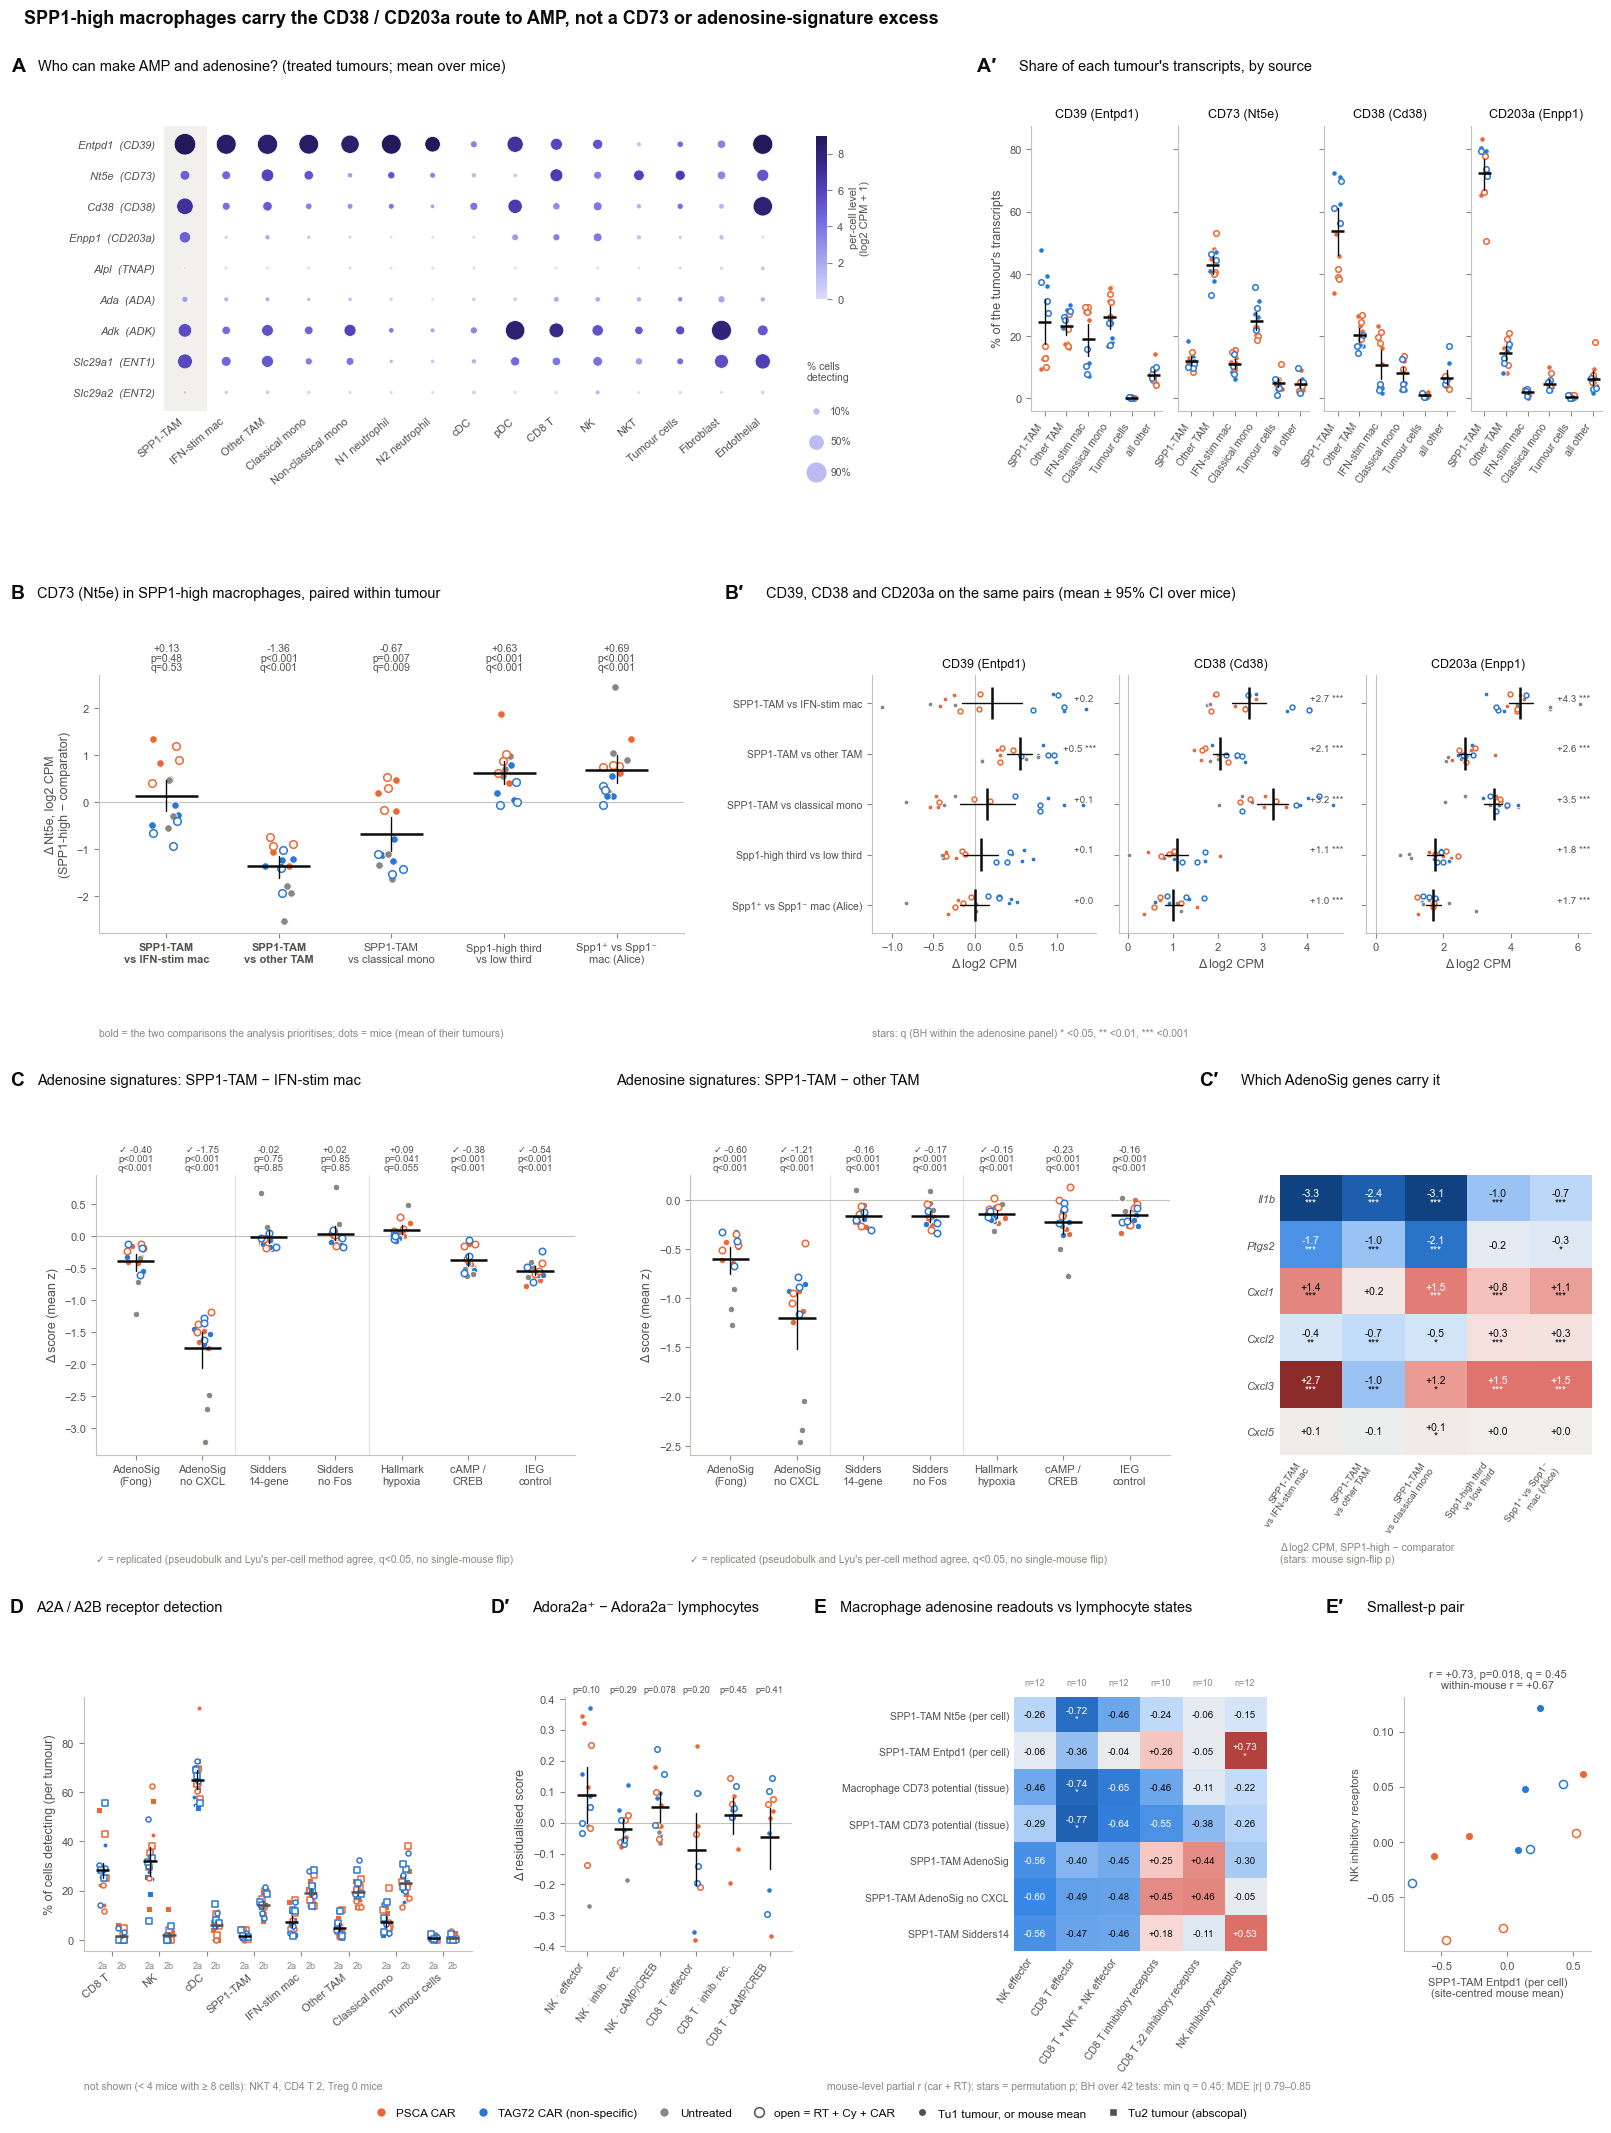

fig6 companion tables: 423 displayed statistics (10 panels), 1321 source-data rows


In [ ]:
ARM_OF_MOUSE = design.drop_duplicates("mouse").set_index("mouse").arm
COMP_LAB = {"SPP1-TAM vs IFN-stim. Mac": "SPP1-TAM\nvs IFN-stim mac", "SPP1-TAM vs other TAM": "SPP1-TAM\nvs other TAM",
            "SPP1-TAM vs classical mono": "SPP1-TAM\nvs classical mono",
            "Spp1-high vs Spp1-low third": "Spp1-high third\nvs low third", "Spp1+ vs Spp1− Mac (lvl4)": "Spp1⁺ vs Spp1⁻\nmac (Alice)"}


def fmt_p(p):
    return "n/a" if not np.isfinite(p) else "p<0.001" if p < 0.001 else f"p={p:.3f}" if p < 0.1 else f"p={p:.2f}"


def fmt_q(q):
    return "" if not np.isfinite(q) else "q<0.001" if q < 0.001 else f"q={q:.3f}" if q < 0.1 else f"q={q:.2f}"


def dot(ax, x, y, arm, site=None, s=30, z=3):
    col = CAR_COL[CAR_OF[arm]]; rt = arm.startswith("RT")
    ax.scatter(np.atleast_1d(x), np.atleast_1d(y), s=s, marker=SITE_MARK.get(site, "o"), zorder=z,
               facecolor="white" if rt else col, edgecolor=col if rt else "white", linewidth=1.1 if rt else 0.7)


def mouse_strip(ax, values, x, jitter=0.13, s=28, horizontal=False):
    """values: Series indexed by mouse -> one dot per mouse."""
    g_ = np.random.default_rng(SEED + int(round(x * 100)))
    for mo, v in values.dropna().items():
        j = g_.uniform(-jitter, jitter)
        if horizontal: dot(ax, v, x + j, ARM_OF_MOUSE[mo], s=s)
        else: dot(ax, x + j, v, ARM_OF_MOUSE[mo], s=s)


def mean_ci(ax, x, m, lo, hi, w=0.28, horizontal=False, color=INK):
    if not np.isfinite(m): return
    if horizontal:
        ax.plot([m, m], [x - w, x + w], color=color, lw=1.8, zorder=5, solid_capstyle="butt")
        ax.plot([lo, hi], [x, x], color=color, lw=1.0, zorder=5)
    else:
        ax.plot([x - w, x + w], [m, m], color=color, lw=1.8, zorder=5, solid_capstyle="butt")
        ax.plot([x, x], [lo, hi], color=color, lw=1.0, zorder=5)


def top_note(ax, x, text, fs=7, color=None):
    ax.text(x, 1.01, text, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=fs,
            color=color or INK2, linespacing=0.95)


def panel_label(sf, letter, title, x=0.0, y=1.0):
    sf.text(x + 0.004, y - 0.006, letter, fontsize=14, fontweight="bold", va="top", ha="left", color=INK)
    tr = mpl.transforms.offset_copy(sf.transSubfigure, fig=sf.figure, x=11 * len(letter) + 8, y=-1.5, units="points")
    sf.text(x + 0.004, y - 0.006, title, fontsize=10.5, va="top", ha="left", color=INK, transform=tr)


def text_color(rgba):
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    return INK if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.32 else "white"


def stars(p): return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def annotated_heatmap(ax, M, vmax, fmt="{:+.1f}", star_mat=None, fs=7.5):
    norm = TwoSlopeNorm(0, -vmax, vmax)
    ax.imshow(np.ma.masked_invalid(M.values.astype(float)), cmap=DIV, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if not np.isfinite(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=fs - 1, color=MUTED); continue
            s = fmt.format(v) + (("\n" + star_mat.values[i, j]) if star_mat is not None and star_mat.values[i, j] else "")
            ax.text(j, i, s, ha="center", va="center", fontsize=fs, color=text_color(DIV(norm(v))), linespacing=0.9)
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    for sp_ in ax.spines.values(): sp_.set_visible(False)
    ax.tick_params(length=0)
    return norm


def legend_car_rt_site(fig, y=0.0, extra=()):
    h = [Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec="white", ms=7, label="PSCA CAR"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec="white", ms=7, label="TAG72 CAR (non-specific)"),
         Line2D([], [], marker="o", ls="", mfc=C_NOTX, mec="white", ms=7, label="Untreated"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, mew=1.1, ms=7, label="open = RT + Cy + CAR"),
         Line2D([], [], marker="o", ls="", mfc=INK2, mec="white", ms=6, label="Tu1 tumour, or mouse mean"),
         Line2D([], [], marker="s", ls="", mfc=INK2, mec="white", ms=6, label="Tu2 tumour (abscopal)")] + list(extra)
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, y), frameon=False, ncol=len(h), fontsize=8.5,
               handletextpad=0.3, columnspacing=1.3)


def mouse_vals(per_sample):
    v = per_sample.dropna()
    return v.groupby(mouse_of(v.index)).mean()


# results the figure title states (read from the tables, not typed in)
cd38_all = PG[(PG.gene == "Cd38") & (PG.measure == "log2 CPM")]
nt5e_all = PG[(PG.gene == "Nt5e") & (PG.measure == "log2 CPM")].set_index("comparison")
FIG6_TITLE = ("SPP1-high macrophages carry the CD38 / CD203a route to AMP, not a CD73 or adenosine-signature excess"
              if (cd38_all.mean_diff > 0).all() and nt5e_all.loc["SPP1-TAM vs other TAM", "mean_diff"] < 0
              else "Adenosine pathway transcripts in SPP1-high macrophages")

fig = plt.figure(figsize=(16, 20.5))
R = fig.subfigures(4, 1, height_ratios=[1.0, 0.92, 1.0, 1.0], hspace=0.035)

# ---------- A: ectoenzyme map
sA, sA2 = R[0].subfigures(1, 2, width_ratios=[0.6, 0.4], wspace=0.02)
panel_label(sA, "A", "Who can make AMP and adenosine? (treated tumours; mean over mice)")
axA = sA.add_axes([0.16, 0.30, 0.66, 0.56])
A_GENES = ECTO + CATAB + TRANSP
A_NAMES = ["CD39", "CD73", "CD38", "CD203a", "TNAP", "ADA", "ADK", "ENT1", "ENT2"]
A_POPS = [p for p in POPS if COV.loc[p, "treated_mice_ge10"] >= 4]
dA = MAP[MAP.gene.isin(A_GENES) & MAP.population.isin(A_POPS)]
vmax = np.nanpercentile(dA.level_mouse_mean, 98)
axA.axvspan(A_POPS.index("SPP1_TAM") - 0.5, A_POPS.index("SPP1_TAM") + 0.5, color="#f1f0ec", zorder=0)
for i, g in enumerate(A_GENES):
    d = dA[dA.gene == g].set_index("population").reindex(A_POPS)
    axA.scatter(np.arange(len(A_POPS)), np.full(len(A_POPS), i), s=6 + 2.6 * d.pct_detected_mouse_mean.fillna(0),
                c=d.level_mouse_mean.values, cmap=SEQ, vmin=0, vmax=vmax, edgecolor="white", linewidth=0.5, zorder=3)
axA.set_xticks(range(len(A_POPS))); axA.set_xticklabels([lab(p) for p in A_POPS], rotation=40, ha="right")
axA.set_yticks(range(len(A_GENES))); axA.set_yticklabels([f"{g}  ({n})" for g, n in zip(A_GENES, A_NAMES)])
for t in axA.get_yticklabels(): t.set_fontstyle("italic")
axA.invert_yaxis(); axA.set_xlim(-0.6, len(A_POPS) - 0.4); axA.set_ylim(len(A_GENES) - 0.4, -0.6)
for sp_ in axA.spines.values(): sp_.set_visible(False)
axA.tick_params(length=0)
cax = sA.add_axes([0.85, 0.52, 0.012, 0.32])
cb = sA.colorbar(mpl.cm.ScalarMappable(cmap=SEQ, norm=mpl.colors.Normalize(0, vmax)), cax=cax)
cb.set_label("per-cell level\n(log2 CPM + 1)", fontsize=8); cb.outline.set_visible(False)
for k_, pct in enumerate((10, 50, 90)):
    sA.text(0.865, 0.30 - k_ * 0.06, f"{pct}%", fontsize=7.5, va="center", color=INK2)
    sA.add_artist(Line2D([0.85], [0.30 - k_ * 0.06], marker="o", ls="", ms=np.sqrt(6 + 2.6 * pct), mfc="#bdbcf2",
                         mec="white", transform=sA.transSubfigure))
sA.text(0.84, 0.36, "% cells\ndetecting", fontsize=7.5, color=INK2)
show_source("6A", dA[["population", "gene", "level_mouse_mean", "pct_detected_mouse_mean", "share_mouse_mean", "n_mice"]])
for _, r in dA.iterrows():
    show_stat("6A", population=r.population, gene=r.gene, statistic="per-cell level, log2 CPM+1 (mean over treated mice)",
              value=r.level_mouse_mean, n_mice=r.n_mice)
    show_stat("6A", population=r.population, gene=r.gene, statistic="% cells detecting (mean over treated mice)",
              value=r.pct_detected_mouse_mean, n_mice=r.n_mice_det)

panel_label(sA2, "A′", "Share of each tumour's transcripts, by source")
SRC_POPS = ["SPP1_TAM", "TAM_other", "IFN_stimulated_Mac", "Classical_Mono", "Cancer_cell"]
axs = sA2.subplots(1, 4, sharey=True, gridspec_kw=dict(left=0.09, right=0.99, top=0.86, bottom=0.30, wspace=0.12))
for ax, (g, nm) in zip(axs, [("Entpd1", "CD39"), ("Nt5e", "CD73"), ("Cd38", "CD38"), ("Enpp1", "CD203a")]):
    S_ = SHARE_M[g].copy(); S_["other"] = 1 - S_[[p for p in SRC_POPS if p in S_]].sum(1)
    for i, p_ in enumerate(SRC_POPS + ["other"]):
        v = 100 * S_[p_] if p_ in S_ else pd.Series(dtype=float)
        mouse_strip(ax, v, i, s=16, jitter=0.16)
        bt = v.values[rng.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
        mean_ci(ax, i, v.mean(), np.percentile(bt, 2.5), np.percentile(bt, 97.5), w=0.3)
        show_stat("6A′", gene=g, population=p_, statistic="% of tumour's transcripts (mean over treated mice)",
                  value=v.mean(), ci_lo=np.percentile(bt, 2.5), ci_hi=np.percentile(bt, 97.5), n_mice=len(v))
        show_source("6A′", pd.DataFrame({"gene": g, "population": p_, "mouse": v.index, "value": v.values}))
    ax.set_xticks(range(len(SRC_POPS) + 1)); ax.set_xticklabels([lab(p) for p in SRC_POPS] + ["all other"], rotation=55, ha="right", fontsize=7.5)
    ax.set_title(f"{nm} ({g})", fontsize=9, color=INK)
    ax.set_xlim(-0.6, len(SRC_POPS) + 0.4)
axs[0].set_ylabel("% of the tumour's transcripts")

# ---------- B: CD73 paired
sB, sB2 = R[1].subfigures(1, 2, width_ratios=[0.44, 0.56], wspace=0.02)
panel_label(sB, "B", "CD73 (Nt5e) in SPP1-high macrophages, paired within tumour")
axB = sB.add_axes([0.13, 0.25, 0.84, 0.55])
for i, cname in enumerate(COMPS):
    ga, gb = COMPS[cname]
    a, b = pb_level(ga, "Nt5e"), pb_level(gb, "Nt5e"); smp = a.index.intersection(b.index)
    mv = mouse_vals(a.loc[smp] - b.loc[smp]); mouse_strip(axB, mv, i, s=30)
    r = nt5e_all.loc[cname]
    mean_ci(axB, i, r.mean_diff, r.ci_lo, r.ci_hi)
    top_note(axB, i, f"{r.mean_diff:+.2f}\n{fmt_p(r.p_signflip)}\n{fmt_q(r.q_panel)}", fs=7.5)
    show_stat("6B", comparison=cname, gene="Nt5e", statistic="paired Δ log2 CPM (A − B), mean over mice", value=r.mean_diff,
              ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, p_signflip=r.p_signflip, q_panel=r.q_panel,
              frac_mice_same_sign=r.frac_mice_same_sign, lomo_flips=r.lomo_flips)
    show_source("6B", pd.DataFrame({"comparison": cname, "mouse": mv.index, "value": mv.values}))
axB.axhline(0, color=AXIS, lw=0.8, zorder=1)
axB.set_xticks(range(len(COMPS))); axB.set_xticklabels([COMP_LAB[c] for c in COMPS], fontsize=8)
for t, c in zip(axB.get_xticklabels(), COMPS):
    if c in PRIMARY: t.set_fontweight("bold")
axB.set_ylabel("Δ Nt5e, log2 CPM\n(SPP1-high − comparator)"); axB.set_xlim(-0.6, len(COMPS) - 0.4)
sB.text(0.13, 0.03, "bold = the two comparisons the analysis prioritises; dots = mice (mean of their tumours)", fontsize=7.5, color=MUTED)

panel_label(sB2, "B′", "CD39, CD38 and CD203a on the same pairs (mean ± 95% CI over mice)")
axs = sB2.subplots(1, 3, sharey=True, gridspec_kw=dict(left=0.17, right=0.98, top=0.80, bottom=0.25, wspace=0.10))
for ax, (g, nm) in zip(axs, [("Entpd1", "CD39"), ("Cd38", "CD38"), ("Enpp1", "CD203a")]):
    for i, cname in enumerate(COMPS):
        ga, gb = COMPS[cname]
        a, b = pb_level(ga, g), pb_level(gb, g); smp = a.index.intersection(b.index)
        mv = mouse_vals(a.loc[smp] - b.loc[smp]); mouse_strip(ax, mv, i, s=12, jitter=0.18, horizontal=True)
        r = PG[(PG.comparison == cname) & (PG.gene == g) & (PG.measure == "log2 CPM")].iloc[0]
        mean_ci(ax, i, r.mean_diff, r.ci_lo, r.ci_hi, w=0.32, horizontal=True)
        ax.text(1.0, i, f"{r.mean_diff:+.1f} {stars(r.q_panel)}", transform=ax.get_yaxis_transform(), ha="right", va="bottom",
                fontsize=7, color=INK2)
        show_stat("6B′", comparison=cname, gene=g, statistic="paired Δ log2 CPM (A − B), mean over mice", value=r.mean_diff,
                  ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, p_signflip=r.p_signflip, q_panel=r.q_panel)
        show_source("6B′", pd.DataFrame({"comparison": cname, "gene": g, "mouse": mv.index, "value": mv.values}))
    ax.axvline(0, color=AXIS, lw=0.8, zorder=1); ax.set_title(f"{nm} ({g})", fontsize=9, color=INK)
    ax.set_xlabel("Δ log2 CPM")
axs[0].set_yticks(range(len(COMPS))); axs[0].set_yticklabels([COMP_LAB[c].replace("\n", " ") for c in COMPS], fontsize=7.5)
axs[0].invert_yaxis()
sB2.text(0.17, 0.03, "stars: q (BH within the adenosine panel) * <0.05, ** <0.01, *** <0.001", fontsize=7.5, color=MUTED)

# ---------- C: signatures
sC1, sC2, sC3 = R[2].subfigures(1, 3, width_ratios=[0.37, 0.37, 0.26], wspace=0.02)
C_SC = ["AdenoSig", "AdenoSig_noCXCL", "Sidders14", "Sidders14_noFos", "HALLMARK_HYPOXIA", "cAMP_CREB", "IEG_dissociation"]
C_LAB = ["AdenoSig\n(Fong)", "AdenoSig\nno CXCL", "Sidders\n14-gene", "Sidders\nno Fos", "Hallmark\nhypoxia", "cAMP /\nCREB", "IEG\ncontrol"]
for sf, cname, letter in [(sC1, PRIMARY[0], "C"), (sC2, PRIMARY[1], "")]:
    panel_label(sf, letter, f"Adenosine signatures: SPP1-TAM − {'IFN-stim mac' if 'IFN' in cname else 'other TAM'}")
    ax = sf.add_axes([0.15, 0.24, 0.82, 0.55])
    A_ = SC_PB[SC_PB.group == COMPS[cname][0]].set_index("sample"); B_ = SC_PB[SC_PB.group == COMPS[cname][1]].set_index("sample")
    smp = A_.index.intersection(B_.index)
    for i, k in enumerate(C_SC):
        mv = mouse_vals(A_.loc[smp, k] - B_.loc[smp, k]); mouse_strip(ax, mv, i, s=22)
        r = SIG[(SIG.comparison == cname) & (SIG.score == k)].iloc[0]
        mean_ci(ax, i, r.pb_mean_diff, r.pb_ci_lo, r.pb_ci_hi)
        top_note(ax, i, ("✓ " if r.replicated else "") + f"{r.pb_mean_diff:+.2f}\n{fmt_p(r.pb_p_signflip)}\n{fmt_q(r.pb_q)}", fs=7)
        show_stat("6C", comparison=cname, score=k, statistic="paired Δ score (common-scale mean z), mean over mice",
                  value=r.pb_mean_diff, ci_lo=r.pb_ci_lo, ci_hi=r.pb_ci_hi, n_mice=r.pb_n_mice, p_signflip=r.pb_p_signflip,
                  q_family=r.pb_q, lyu_method_diff=r.get("lyu_mean_diff"), lyu_method_p=r.get("lyu_p_signflip"),
                  random_set_percentile=r.get("rand_pct"), lomo_flips=r.pb_lomo_flips, replicated=r.replicated)
        show_source("6C", pd.DataFrame({"comparison": cname, "score": k, "mouse": mv.index, "value": mv.values}))
    ax.axhline(0, color=AXIS, lw=0.8, zorder=1)
    for xb in (1.5, 3.5): ax.axvline(xb, color=GRID, lw=0.8, zorder=0)
    ax.set_xticks(range(len(C_SC))); ax.set_xticklabels(C_LAB, fontsize=8); ax.set_xlim(-0.6, len(C_SC) - 0.4)
    ax.set_ylabel("Δ score (mean z)")
    sf.text(0.15, 0.03, "✓ = replicated (pseudobulk and Lyu's per-cell method agree, q<0.05, no single-mouse flip)",
            fontsize=7.5, color=MUTED)

panel_label(sC3, "C′", "Which AdenoSig genes carry it")
axC3 = sC3.add_axes([0.20, 0.24, 0.76, 0.55])
Hm = AG.pivot(index="gene", columns="comparison", values="mean_diff").reindex(index=SIGS["AdenoSig"], columns=list(COMPS))
Hs = AG.pivot(index="gene", columns="comparison", values="p").reindex(index=SIGS["AdenoSig"], columns=list(COMPS)).applymap(
    lambda p: stars(p) if np.isfinite(p) else "")
annotated_heatmap(axC3, Hm, vmax=3, star_mat=Hs, fs=7.5)
axC3.set_yticklabels(Hm.index, fontstyle="italic")
axC3.set_xticklabels([COMP_LAB[c] for c in Hm.columns], rotation=55, ha="right", fontsize=7)
sC3.text(0.20, 0.03, "Δ log2 CPM, SPP1-high − comparator\n(stars: mouse sign-flip p)", fontsize=7.5, color=MUTED)
for (g, c), v in Hm.stack().items():
    show_stat("6C′", gene=g, comparison=c, statistic="paired Δ log2 CPM, mean over mice", value=v,
              p_signflip=AG[(AG.gene == g) & (AG.comparison == c)].p.iloc[0])
show_source("6C′", AG)

# ---------- D: receptors
sD, sD2, sE, sE2 = R[3].subfigures(1, 4, width_ratios=[0.30, 0.20, 0.32, 0.18], wspace=0.02)
panel_label(sD, "D", "A2A / A2B receptor detection")
axD = sD.add_axes([0.16, 0.30, 0.82, 0.50])
D_POPS = [p for p in ["CD8_T", "NK", "cDC", "SPP1_TAM", "IFN_stimulated_Mac", "TAM_other", "Classical_Mono", "Cancer_cell"]
          if p in REC.index and REC.loc[p, "n_mice"] >= 4]
srcD = pd.concat(rec_src, ignore_index=True)
for i, p_ in enumerate(D_POPS):
    for g, off in [("Adora2a", -0.2), ("Adora2b", 0.2)]:
        s_ = srcD[srcD.population == p_]
        g2 = np.random.default_rng(SEED + i)
        for _, r in s_.iterrows():
            dot(axD, i + off + g2.uniform(-0.07, 0.07), r[g], r.arm, site=r.site, s=13)
        m, lo, hi = REC.loc[p_, [f"{g}_pct", f"{g}_ci_lo", f"{g}_ci_hi"]]
        mean_ci(axD, i + off, m, lo, hi, w=0.14, color=INK if g == "Adora2a" else INK2)
        show_stat("6D", population=p_, gene=g, statistic="% cells detecting (mean over treated mice)", value=m, ci_lo=lo,
                  ci_hi=hi, n_mice=int(REC.loc[p_, "n_mice"]), n_samples=int(REC.loc[p_, "n_samples"]),
                  median_cells=REC.loc[p_, "median_cells"])
    axD.text(i - 0.2, -0.04, "2a", transform=axD.get_xaxis_transform(), ha="center", va="top", fontsize=6.5, color=MUTED)
    axD.text(i + 0.2, -0.04, "2b", transform=axD.get_xaxis_transform(), ha="center", va="top", fontsize=6.5, color=MUTED)
axD.set_xticks(range(len(D_POPS))); axD.set_xticklabels([lab(p) for p in D_POPS], rotation=40, ha="right")
axD.tick_params(axis="x", pad=11); axD.set_xlim(-0.6, len(D_POPS) - 0.4)
axD.set_ylabel("% of cells detecting (per tumour)")
nots = [f"{lab(p)} {int(REC.loc[p, 'n_mice']) if p in REC.index else 0}" for p in ["NKT", "CD4_T", "Treg"]]
sD.text(0.16, 0.03, "not shown (< 4 mice with ≥ 8 cells): " + ", ".join(nots) + " mice", fontsize=7.5, color=MUTED)
show_source("6D", srcD)

panel_label(sD2, "D′", "Adora2a⁺ − Adora2a⁻ lymphocytes")
axD2 = sD2.add_axes([0.24, 0.30, 0.72, 0.50])
srcD2 = pd.concat(ph_src, ignore_index=True)
xl = []
for i, ((p_, mn), d) in enumerate(PH.groupby(["population", "module"], sort=False)):
    mv = srcD2[(srcD2.population == p_) & (srcD2.module == mn)].set_index("mouse").value
    mouse_strip(axD2, mv, i, s=16)
    r = d.iloc[0]
    mean_ci(axD2, i, r.mean_diff, r.ci_lo, r.ci_hi, w=0.25)
    top_note(axD2, i, f"{fmt_p(r.p_signflip)}", fs=6.5)
    show_stat("6D′", population=p_, module=mn, statistic="Adora2a+ − Adora2a− cells, residualised module score, mean over mice",
              value=r.mean_diff, ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, p_signflip=r.p_signflip, q=r.q,
              cells_pos=r.cells_pos, cells_total=r.cells_total)
    xl.append(f"{lab(p_)} · " + {"effector (no Ccl5)": "effector", "inhibitory receptors (no Entpd1)": "inhib. rec.",
                                  "cAMP / CREB module": "cAMP/CREB"}[mn])
axD2.axhline(0, color=AXIS, lw=0.8); axD2.set_xticks(range(len(xl))); axD2.set_xticklabels(xl, rotation=55, ha="right", fontsize=7.5)
axD2.set_ylabel("Δ residualised score"); axD2.set_xlim(-0.6, len(xl) - 0.4)
show_source("6D′", srcD2)

# ---------- E: associations
panel_label(sE, "E", "Macrophage adenosine readouts vs lymphocyte states")
axE = sE.add_axes([0.40, 0.30, 0.50, 0.50])
Hm = AS.pivot(index="predictor", columns="outcome", values="partial_r").reindex(index=list(PRED), columns=list(OUTC))
Hp = AS.pivot(index="predictor", columns="outcome", values="p_mouse").reindex(index=list(PRED), columns=list(OUTC))
annotated_heatmap(axE, Hm, vmax=1, fmt="{:+.2f}", star_mat=Hp.applymap(lambda p: stars(p) if np.isfinite(p) else ""), fs=7)
axE.set_yticklabels(Hm.index, fontsize=7.5)
axE.set_xticklabels([o.replace(" with >= 2 ", " ≥2 ") for o in Hm.columns], rotation=55, ha="right", fontsize=7.5)
nm_ = AS.groupby("outcome").n_mice.first().reindex(Hm.columns)
for j, n in enumerate(nm_.values):
    axE.text(j, -0.75, f"n={int(n)}", ha="center", va="bottom", fontsize=6.5, color=MUTED)
sE.text(0.03, 0.03, f"mouse-level partial r (car + RT); stars = permutation p; BH over {len(AS)} tests: "
        f"min q = {AS.q_mouse.min():.2f}; MDE |r| {AS.mde_r.min():.2f}–{AS.mde_r.max():.2f}", fontsize=7.5, color=MUTED)
for _, r in AS.iterrows():
    show_stat("6E", predictor=r.predictor, outcome=r.outcome, statistic="mouse-level partial r (car + RT), Freedman-Lane",
              value=r.partial_r, ci_lo=r.get("r_ci_lo"), ci_hi=r.get("r_ci_hi"), n_mice=r.n_mice, p=r.p_mouse, q=r.q_mouse,
              r_within_mouse=r.get("r_within"), p_within=r.get("p_within"), r_sample_level=r.partial_r_sample,
              p_sample_level=r.p_sample, mde_r=r.mde_r, lomo_flips=r.get("lomo_flips"), replicated=r.replicated)
show_source("6E", AS.rename(columns={"partial_r": "value"}))

panel_label(sE2, "E′", "Smallest-p pair")
axE2 = sE2.add_axes([0.28, 0.30, 0.66, 0.50])
best = AS.sort_values("p_mouse").iloc[0]
mx, my = mouse_means(PRED[best.predictor]), mouse_means(OUTC[best.outcome][0])
mi = mx.index.intersection(my.index)
for mo in mi: dot(axE2, mx.loc[mo, "v"], my.loc[mo, "v"], mx.loc[mo, "arm"], s=34)
axE2.set_xlabel(f"{best.predictor}\n(site-centred mouse mean)", fontsize=8)
axE2.set_ylabel(best.outcome, fontsize=8)
axE2.set_title(f"r = {best.partial_r:+.2f}, {fmt_p(best.p_mouse)}, q = {best.q_mouse:.2f}\nwithin-mouse r = {best.get('r_within', np.nan):+.2f}",
               fontsize=8, color=INK2)
show_source("6E′", pd.DataFrame({"mouse": mi, "x": mx.loc[mi, "v"].values, "y": my.loc[mi, "v"].values,
                                 "arm": mx.loc[mi, "arm"].values, "predictor": best.predictor, "outcome": best.outcome}))
show_stat("6E′", predictor=best.predictor, outcome=best.outcome, statistic="mouse-level partial r (car + RT)",
          value=best.partial_r, n_mice=best.n_mice, p=best.p_mouse, q=best.q_mouse, r_within_mouse=best.get("r_within"))

legend_car_rt_site(fig, y=-0.012)
fig.suptitle(FIG6_TITLE, x=0.01, ha="left", y=1.022, fontsize=13, fontweight="bold", color=INK)
save_figure(fig, "fig6_adenosine_pathway")
plt.show()

STATS6 = pd.DataFrame(DISPLAYED); STATS6.to_csv(FIG/"fig6_adenosine_pathway_displayed_stats.csv", index=False)
SRC6 = pd.concat(SOURCE, ignore_index=True); SRC6.to_csv(FIG/"fig6_adenosine_pathway_source_data.csv", index=False)
print(f"fig6 companion tables: {len(STATS6)} displayed statistics ({STATS6.panel.nunique()} panels), {len(SRC6)} source-data rows")

## 14. Summary

In [ ]:
def sig_row(c, k): return SIG[(SIG.comparison == c) & (SIG.score == k)].iloc[0]


def pg_row(c, g, meas="log2 CPM"): return PG[(PG.comparison == c) & (PG.gene == g) & (PG.measure == meas)].iloc[0]


print("=" * 110); print("SUMMARY — report these back"); print("=" * 110)
print(f"[data] {len(meta):,} cells, {len(design)} tumours, {design.mouse.nunique()} mice ({design.loc[TREATED].mouse.nunique()} treated). "
      f"Mouse = unit. Mouse AdenoSig = {SIGS['AdenoSig']} (6/8 human genes; CXCL8 has no ortholog, CXCL6 -> Cxcl5); "
      f"Sidders 14/14 (GPI -> Gpi1).")

print("\n1. THREE STRONGEST FINDINGS (paired within tumour; mean over mice [95% CI])")
c38 = [pg_row(c, "Cd38") for c in COMPS]; e1 = [pg_row(c, "Enpp1") for c in COMPS]
print(f"  (i) SPP1-high macrophages are the CD38 / CD203a (Enpp1) source — the NAD+ -> AMP route — under all 5 SPP1 definitions.")
print(f"      Cd38  Δ log2 CPM {pg_row(PRIMARY[0], 'Cd38').mean_diff:+.2f} vs IFN-stim, {pg_row(PRIMARY[1], 'Cd38').mean_diff:+.2f} vs other TAM "
      f"(range over definitions {min(r.mean_diff for r in c38):+.2f} to {max(r.mean_diff for r in c38):+.2f}; max q "
      f"{max(r.q_panel for r in c38):.1g}; >= {100*min(r.frac_mice_same_sign for r in c38):.0f}% of mice same sign in every definition); "
      f"{100*CPOOL.loc['SPP1_TAM','Cd38']:.0f}% of the tumour's Cd38 transcripts.")
print(f"      Enpp1 Δ {pg_row(PRIMARY[0], 'Enpp1').mean_diff:+.2f} / {pg_row(PRIMARY[1], 'Enpp1').mean_diff:+.2f} "
      f"(range {min(r.mean_diff for r in e1):+.2f} to {max(r.mean_diff for r in e1):+.2f}); {100*CPOOL.loc['SPP1_TAM','Enpp1']:.0f}% of the tumour's Enpp1.")
r_o, r_i, r_t, r_a = (nt5e_all.loc[c] for c in ["SPP1-TAM vs other TAM", "SPP1-TAM vs IFN-stim. Mac", "Spp1-high vs Spp1-low third",
                                                 "Spp1+ vs Spp1− Mac (lvl4)"])
print(f"  (ii) CD73 (Nt5e) is NOT an SPP1-TAM feature as defined by the signature: {r_o.mean_diff:+.2f} [{r_o.ci_lo:+.2f},{r_o.ci_hi:+.2f}] vs other TAM "
      f"({fmt_q(r_o.q_panel)}), {r_i.mean_diff:+.2f} [{r_i.ci_lo:+.2f},{r_i.ci_hi:+.2f}] vs IFN-stim (p={r_i.p_signflip:.2f}); SPP1-TAMs hold "
      f"{100*CPOOL.loc['SPP1_TAM','Nt5e']:.0f}% of CD73 transcripts vs {100*CPOOL.loc['TAM_other','Nt5e']:.0f}% for other TAMs.")
print(f"       Cutting macrophages by Spp1 itself reverses the sign: Spp1-high third {r_t.mean_diff:+.2f} [{r_t.ci_lo:+.2f},{r_t.ci_hi:+.2f}], "
      f"Alice Spp1+ {r_a.mean_diff:+.2f} [{r_a.ci_lo:+.2f},{r_a.ci_hi:+.2f}] ({fmt_q(r_t.q_panel)}, {fmt_q(r_a.q_panel)}). Per-cell Nt5e "
      f"is highest in {lab('state_' + STL.Nt5e.idxmax())} ({STL.Nt5e.max():.1f}) and lowest in {lab('state_' + STL.Nt5e.idxmin())} "
      f"({STL.Nt5e.min():.1f}), which makes up {100*STL.loc['Apoe_high_Mac','share_of_SPP1TAM_cells']:.0f}% of SPP1-TAMs. "
      f"Within states (7b), Spp1 vs Nt5e rho: "
      + ", ".join(f"{lab('state_'+r.state)} {r.mean_diff:+.2f}" for _, r in WS[WS.gene == "Nt5e"].iterrows()) + ".")
a_i, a_o, n_i, s_i = sig_row(PRIMARY[0], "AdenoSig"), sig_row(PRIMARY[1], "AdenoSig"), sig_row(PRIMARY[0], "AdenoSig_noCXCL"), sig_row(PRIMARY[0], "Sidders14")
print(f"  (iii) Adenosine-response signatures are not higher in SPP1-TAMs: AdenoSig {a_i.pb_mean_diff:+.2f} z vs IFN-stim, {a_o.pb_mean_diff:+.2f} vs "
      f"other TAM ({fmt_q(a_i.pb_q)}, {fmt_q(a_o.pb_q)}; LOWER), carried by Il1b ({AG[(AG.gene=='Il1b')&(AG.comparison==PRIMARY[0])].mean_diff.iloc[0]:+.1f} log2) and "
      f"Ptgs2 ({AG[(AG.gene=='Ptgs2')&(AG.comparison==PRIMARY[0])].mean_diff.iloc[0]:+.1f}); removing CXCL makes it more negative "
      f"({n_i.pb_mean_diff:+.2f}); Sidders {s_i.pb_mean_diff:+.2f} [{s_i.pb_ci_lo:+.2f},{s_i.pb_ci_hi:+.2f}], p={s_i.pb_p_signflip:.2f}.")

print("\n2. FDR-SIGNIFICANT AND REPLICATED")
rep_g = PG[(PG.measure == "log2 CPM") & (PG.q_panel < 0.05) & (PG.lomo_flips == 0) & (PG.frac_mice_same_sign >= 0.8)]
rep_g = rep_g.merge(pde_p[["comparison", "gene", "log2FoldChange", "panel_padj"]], on=["comparison", "gene"])
rep_g = rep_g[(np.sign(rep_g.mean_diff) == np.sign(rep_g.log2FoldChange)) & (rep_g.panel_padj < 0.05)]
print(f"  state comparisons, gene level (sign-flip q<0.05 AND DESeq2 panel q<0.05 same sign, >=80% of mice, no LOMO flip): {len(rep_g)}")
for c_, d in rep_g.groupby("comparison", sort=False):
    print(f"    {c_:<28s} " + ", ".join(f"{r.gene} {r.mean_diff:+.2f}" for _, r in d.sort_values("mean_diff").iterrows()))
sr = SIG[SIG.replicated & SIG.score.isin(list(SIGS) + ["HALLMARK_HYPOXIA"])]
print("  signatures (both readouts, q<0.05, no LOMO flip): " + "; ".join(
    f"{r.score} {'UP' if r.pb_mean_diff > 0 else 'DOWN'} in SPP1-high [{r.comparison}] {r.pb_mean_diff:+.2f}" for _, r in sr.iterrows()))
print("  treatment (exact relabelling; both strata/backgrounds, p<0.05, q<0.10, no LOMO flip): " + ("; ".join(
    f"{r.effect}: {r.measure} @ {lab(r.group)} {r.main_sd:+.1f} SD" for _, r in TX[TX.replicated].iterrows()) or "none"))
print("  02 DESeq2 (both strata, panel BH): " + (", ".join(f"{r.effect}:{r.gene}@{lab(r.group)}({r.lfc_1:+.1f}/{r.lfc_2:+.1f})"
                                                       for _, r in DER[DER.replicated].iterrows()) or "none"))
print("  03 GSEA family sets: " + (", ".join(f"{r.effect}:{r.pathway}@{lab(r.group)}" for _, r in GR[GR.replicated & (GR.family7 != 'control')].iterrows()) or "none"))
print(f"  tissue-level associations (Fig 6E): {int(AS.replicated.sum())} replicated, {int((AS.q_mouse < 0.10).sum())} at q<0.10 of {len(AS)}")

print("\n3. SUGGESTIVE OR INCONCLUSIVE")
for _, r in AS[AS.p_mouse < 0.05].sort_values("p_mouse").iterrows():
    print(f"  association {r.predictor} -> {r.outcome}: r={r.partial_r:+.2f} p={r.p_mouse:.3f} q={r.q_mouse:.2f} (n={int(r.n_mice)} mice; "
          f"within-mouse r={r.get('r_within', np.nan):+.2f}) — nominal only; {int((AS.p_mouse < 0.05).sum())} of {len(AS)} at p<0.05 vs ~{0.05*len(AS):.1f} expected")
hx = [sig_row(c, "HALLMARK_HYPOXIA") for c in COMPS]
print("  hypoxia (Lyu L3): Hallmark Δ " + ", ".join(f"{COMP_LAB[c].split(chr(10))[1] if chr(10) in COMP_LAB[c] else c} {r.pb_mean_diff:+.2f}"
                                                  for c, r in zip(COMPS, hx)) + " z — small and comparator-dependent; GSEA FDR " +
      f"{GSF[GSF.pathway.eq('HALLMARK_HYPOXIA') & GSF.comparison.isin(PRIMARY)].FDR.min():.2f} at best")
for _, r in PH[PH.p_signflip < 0.10].iterrows():
    print(f"  Adora2a+ {lab(r.population)} cells: {r.module} {r.mean_diff:+.3f} p={r.p_signflip:.3f} q={r.q:.2f}")
print(f"  receptor fractions vs treatment: none at p<0.05; MDE {RX.mde_pp.min():.0f}-{RX.mde_pp.max():.0f} pp at 3 v 3 mice")
it = TX[TX.p_inter < 0.05]; n_it = int(TX.p_inter.notna().sum()); ieg_it = it.measure.isin(["cAMP_CREB", "IEG_dissociation"])
print(f"  CAR x RT interactions: {len(it)} of {n_it} at p<0.05 (~{0.05*n_it:.0f} expected) — " +
      ("ABOVE chance. " if len(it) > 2 * 0.05 * n_it else "near chance. ") +
      f"{int(ieg_it.sum())} are the cAMP/CREB and IEG-dissociation modules moving together across "
      f"{it[ieg_it].group.nunique()} populations (a sample-wide immediate-early / handling signal, not cell-type biology). Others: " +
      ", ".join(f"{r.effect}:{r.measure}@{lab(r.group)} ({r.d_1:+.2f} PSCA-bg / {r.d_2:+.2f} TAG72-bg)" if r.effect != "PSCA" else
                f"{r.effect}:{r.measure}@{lab(r.group)} ({r.d_1:+.2f} noRT / {r.d_2:+.2f} RT)" for _, r in it[~ieg_it].sort_values("p_inter").head(8).iterrows())
      + " — single tests, leads only")
cs_ = COS.loc["SPP1_TAM"]
print(f"  CD39/CD73 co-expression in SPP1-TAMs: log OR {cs_.logOR_mean_diff:+.2f} (q={cs_.q:.3f}) — slightly LESS co-detection than library size predicts")

print("\n4. QC / DATA-COVERAGE CONCERNS")
for p_ in ["CD8_T", "NK", "NKT", "CD4_T", "Treg"]:
    c_ = COV.loc[p_]
    print(f"  {lab(p_):<6s} {int(c_.total_cells):>5d} cells; {int(c_.treated_mice_ge10)} treated mice with >= 10 cells "
          f"({int(c_.treated_samples_ge10)} tumours); median {c_.median_cells_per_sample:.0f} cells / tumour")
print(f"  association MDE |r| {AS.mde_r.min():.2f}-{AS.mde_r.max():.2f} at {int(AS.n_mice.min())}-{int(AS.n_mice.max())} mice: only very large effects are visible")
print(f"  Alpl (TNAP) ~0% in every population; Adora2b in CD8 / NK {REC.loc['CD8_T','Adora2b_pct']:.1f}% / {REC.loc['NK','Adora2b_pct']:.1f}%")
print(f"  tumour-cell Entpd1 is mostly ambient macrophage RNA (median intrinsic fraction {IFR.loc['Entpd1','Cancer_cell']:.2f})")
print(f"  AdenoSig in mouse is 4/6 CXCL genes; Cxcl5 is barely expressed in myeloid cells, so 5/6 genes are scored; Sidders' Foxp3 / Lag3 are "
      f"not expressed in myeloid cells (12/14 scored)")
ieg = sig_row(PRIMARY[0], "IEG_dissociation"); cr = sig_row(PRIMARY[0], "cAMP_CREB")
print(f"  the cAMP/CREB module moves with the dissociation IEG control (vs IFN-stim: cAMP {cr.pb_mean_diff:+.2f}, IEG {ieg.pb_mean_diff:+.2f}) "
      f"-> not interpretable as receptor signalling")
print("  the GO / Reactome 'adenosine receptor signalling' sets are receptor / component lists (no target genes; none >= 10 adenosine genes)")
print("  Lyu reported a CD73 PROTEIN increase in mouse Spp1hi-TAMs with a non-significant transcript change; a transcript null cannot rule protein in or out")

print("\n5. WHAT THE RESULTS PERMIT US TO CLAIM")
if (cd38_all.mean_diff > 0).all() and (cd38_all.q_panel < 0.05).all():
    print("  * SPP1-high macrophages in this model are transcriptionally specialised for the CD38 / CD203a (NAD+ -> ADPR -> AMP) arm of "
          "adenosine generation, and are the dominant tissue source of both transcripts. This is a production-POTENTIAL claim only.")
if r_o.mean_diff < 0 and r_t.mean_diff > 0:
    print("  * We cannot claim SPP1-TAMs are a CD73-high state (Lyu L1): the answer depends on the definition. CD73 follows macrophage state "
          "(highest in the non-Apoe TAM states) and rises with Spp1 only when macrophages are cut by Spp1 itself.")
if a_i.pb_mean_diff < 0 and s_i.pb_p_signflip >= 0.05:
    print("  * We cannot claim an elevated adenosine-response signature in SPP1-TAMs (Lyu L2): AdenoSig is lower (Il1b / Ptgs2 low) and Sidders "
          "is flat; the CXCL sensitivity does not rescue it.")
if AS.replicated.sum() == 0:
    print("  * No tissue-level link between macrophage adenosine-production potential and NK / CD8 effector or inhibitory-receptor states "
          f"survives FDR (n = {int(AS.n_mice.min())}-{int(AS.n_mice.max())} mice; effects below |r| ~0.8 are invisible). Absence of evidence, "
          "not evidence of absence.")
px = TX[TX.replicated & (TX.effect == "PSCA") & TX.group.isin(["IFN_stimulated_Mac", "Classical_Mono", "TAM_other", "SPP1_TAM"])]
if len(px):
    print("  * Antigen-specific CAR (PSCA vs TAG72), in both RT strata, shifts myeloid ectoenzyme transcripts: " + "; ".join(
        f"{r.measure} @ {lab(r.group)} {r.main_sd:+.1f} SD" for _, r in px.iterrows()) + " — the IFN-driven state gains CD38 / CD39 "
          "and loses CD73." + (" Radiation (direct or abscopal) leaves no replicated mark on any adenosine readout."
                               if not (TX.replicated & (TX.effect != "PSCA")).any() else ""))
print("  * A2A is transcribed by ~30% of NK and CD8 T cells, so the receptor side is present; whether it is engaged (cAMP) is not readable here.")
print("  * Extracellular adenosine-mediated suppression is neither shown nor excluded; it needs adenosine / AMP measurement, CD73 / CD38 protein "
      "and enzyme activity, or A2AR / CD38 / CD73 blockade in this model.")
print(f"\n[files] {T07}/07_*.csv | {FIG}/fig6_adenosine_pathway.(pdf|svg|png), _displayed_stats.csv, _source_data.csv")
print("=" * 110)

SUMMARY — report these back
[data] 93,548 cells, 29 tumours, 15 mice (12 treated). Mouse = unit. Mouse AdenoSig = ['Il1b', 'Ptgs2', 'Cxcl1', 'Cxcl2', 'Cxcl3', 'Cxcl5'] (6/8 human genes; CXCL8 has no ortholog, CXCL6 -> Cxcl5); Sidders 14/14 (GPI -> Gpi1).

1. THREE STRONGEST FINDINGS (paired within tumour; mean over mice [95% CI])
  (i) SPP1-high macrophages are the CD38 / CD203a (Enpp1) source — the NAD+ -> AMP route — under all 5 SPP1 definitions.
      Cd38  Δ log2 CPM +2.71 vs IFN-stim, +2.06 vs other TAM (range over definitions +1.01 to +3.24; max q 0.0002; >= 100% of mice same sign in every definition); 54% of the tumour's Cd38 transcripts.
      Enpp1 Δ +4.29 / +2.64 (range +1.69 to +4.29); 72% of the tumour's Enpp1.
  (ii) CD73 (Nt5e) is NOT an SPP1-TAM feature as defined by the signature: -1.36 [-1.61,-1.14] vs other TAM (q<0.001), +0.13 [-0.19,+0.47] vs IFN-stim (p=0.48); SPP1-TAMs hold 12% of CD73 transcripts vs 43% for other TAMs.
       Cutting macrophages by Spp1 itself re